In [1]:
!pip install -q transformers sentencepiece accelerate scikit-learn pandas numpy matplotlib seaborn

In [2]:
import os
import torch
import transformers
import pandas as pd
import numpy as np
import sklearn

print("=" * 55)
print("RTE CHALLENGE - ENVIRONMENT CHECK")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("WARNING: GPU is not enabled!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

RTE CHALLENGE - ENVIRONMENT CHECK
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB
Pandas: 2.3.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


In [3]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Random seed set to {SEED}")

Random seed set to 42


In [6]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/rohitsah402/rte-challenge/train.jsonl
/kaggle/input/datasets/rohitsah402/rte-challenge/val.jsonl


In [7]:
import pandas as pd
import json
import os

# Dataset paths
TRAIN_PATH = "/kaggle/input/datasets/rohitsah402/rte-challenge/train.jsonl"
VAL_PATH = "/kaggle/input/datasets/rohitsah402/rte-challenge/val.jsonl"

# Load datasets
train_df = pd.read_json(TRAIN_PATH, lines=True)
val_df = pd.read_json(VAL_PATH, lines=True)

print("=" * 60)
print("DATASET LOADING SUMMARY")
print("=" * 60)

print(f"Training samples   : {len(train_df)}")
print(f"Validation samples : {len(val_df)}")

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(val_df.columns.tolist())

print("\nTraining sample:")
display(train_df.head())

print("\nValidation sample:")
display(val_df.head())

DATASET LOADING SUMMARY
Training samples   : 2490
Validation samples : 277

Training columns:
['premise', 'hypothesis', 'label', 'idx']

Validation columns:
['premise', 'hypothesis', 'label', 'idx']

Training sample:


,premise,hypothesis,label,idx
0,No Weapons of Mass Destruction Found in Iraq Yet.,Weapons of Mass Destruction Found in Iraq.,not_entailment,0
1,"A place of sorrow, after Pope John Paul II die...",Pope Benedict XVI is the new leader of the Rom...,entailment,1
2,Herceptin was already approved to treat the si...,Herceptin can be used to treat breast cancer.,entailment,2
3,"Judie Vivian, chief executive at ProMedica, a ...",The previous name of Ho Chi Minh City was Saigon.,entailment,3
4,A man is due in court later charged with the m...,Paul Stewart Hutchinson is accused of having s...,not_entailment,4



Validation sample:


,premise,hypothesis,label,idx
0,"Dana Reeve, the widow of the actor Christopher...",Christopher Reeve had an accident.,not_entailment,0
1,"Yet, we now are discovering that antibiotics a...",Bacteria is winning the war against antibiotics.,entailment,1
2,Cairo is now home to some 15 million people - ...,15 million tonnes of rubbish are produced dail...,not_entailment,2
3,"The Amish community in Pennsylvania, which num...",Pennsylvania has the biggest Amish community i...,not_entailment,3
4,Security forces were on high alert after an el...,Security forces were on high alert after a cam...,entailment,4


In [8]:
REQUIRED_COLUMNS = {"premise", "hypothesis", "label"}

for name, df in [("Train", train_df), ("Validation", val_df)]:

    print(f"\n{'=' * 50}")
    print(f"{name.upper()} DATA QUALITY")
    print("=" * 50)

    print("Missing values:")
    print(df[list(REQUIRED_COLUMNS)].isnull().sum())

    print("\nLabel distribution:")
    print(df["label"].value_counts())

    print("\nDuplicate rows:",
          df.duplicated(subset=["premise", "hypothesis"]).sum())

    print("Empty premises:",
          (df["premise"].astype(str).str.strip() == "").sum())

    print("Empty hypotheses:",
          (df["hypothesis"].astype(str).str.strip() == "").sum())


TRAIN DATA QUALITY
Missing values:
label         0
hypothesis    0
premise       0
dtype: int64

Label distribution:
label
entailment        1249
not_entailment    1241
Name: count, dtype: int64

Duplicate rows: 2
Empty premises: 0
Empty hypotheses: 0

VALIDATION DATA QUALITY
Missing values:
label         0
hypothesis    0
premise       0
dtype: int64

Label distribution:
label
entailment        146
not_entailment    131
Name: count, dtype: int64

Duplicate rows: 0
Empty premises: 0
Empty hypotheses: 0


In [9]:
print("Training labels:", train_df["label"].unique())
print("Validation labels:", val_df["label"].unique())

valid_labels = {"entailment", "not_entailment"}

assert set(train_df["label"].unique()).issubset(valid_labels)
assert set(val_df["label"].unique()).issubset(valid_labels)

assert REQUIRED_COLUMNS.issubset(train_df.columns)
assert REQUIRED_COLUMNS.issubset(val_df.columns)

print("\nDataset schema and labels verified!")

Training labels: ['not_entailment' 'entailment']
Validation labels: ['not_entailment' 'entailment']

Dataset schema and labels verified!


In [11]:
# Find duplicate premise-hypothesis pairs
duplicates = train_df[
    train_df.duplicated(
        subset=["premise", "hypothesis"],
        keep=False
    )
].sort_values(["premise", "hypothesis"])

print("DUPLICATE TRAINING EXAMPLES")
display(duplicates[["premise", "hypothesis", "label", "idx"]])

# Check whether duplicate pairs have conflicting labels
if len(duplicates) > 0:
    print("\nLabels for duplicate pairs:")
    print(
        duplicates.groupby(["premise", "hypothesis"])["label"]
        .agg(["count", "nunique", "unique"])
    )

# Check overlap between training and validation
train_pairs = set(zip(train_df["premise"], train_df["hypothesis"]))
val_pairs = set(zip(val_df["premise"], val_df["hypothesis"]))

overlap = train_pairs.intersection(val_pairs)

print("\nDATA LEAKAGE CHECK")
print("Overlapping premise-hypothesis pairs:", len(overlap))

DUPLICATE TRAINING EXAMPLES


,premise,hypothesis,label,idx
459,"The White House pressure, reported by Iraqi of...",Washington is pressing Iraq's leaders to end w...,not_entailment,459
2241,"The White House pressure, reported by Iraqi of...",Washington is pressing Iraq's leaders to end w...,not_entailment,2241
420,"The focus on the engines and the fuel, stems f...",The pilot had been attempting an emergency lan...,not_entailment,420
526,"The focus on the engines and the fuel, stems f...",The pilot had been attempting an emergency lan...,not_entailment,526



Labels for duplicate pairs:
                                                                                                       count  \
premise                                            hypothesis                                                  
The White House pressure, reported by Iraqi off... Washington is pressing Iraq's leaders to end we...      2   
The focus on the engines and the fuel, stems fr... The pilot had been attempting an emergency land...      2   

                                                                                                       nunique  \
premise                                            hypothesis                                                    
The White House pressure, reported by Iraqi off... Washington is pressing Iraq's leaders to end we...        1   
The focus on the engines and the fuel, stems fr... The pilot had been attempting an emergency land...        1   

                                                                 

TRAINING TEXT LENGTH STATISTICS


,premise_words,hypothesis_words
count,2490.00,2490.00
mean,43.57,8.79
std,32.39,4.40
min,4.00,3.00
50%,31.00,8.00
75%,55.00,10.00
90%,96.00,14.00
95%,112.00,18.00
99%,143.00,26.00
max,239.00,41.00


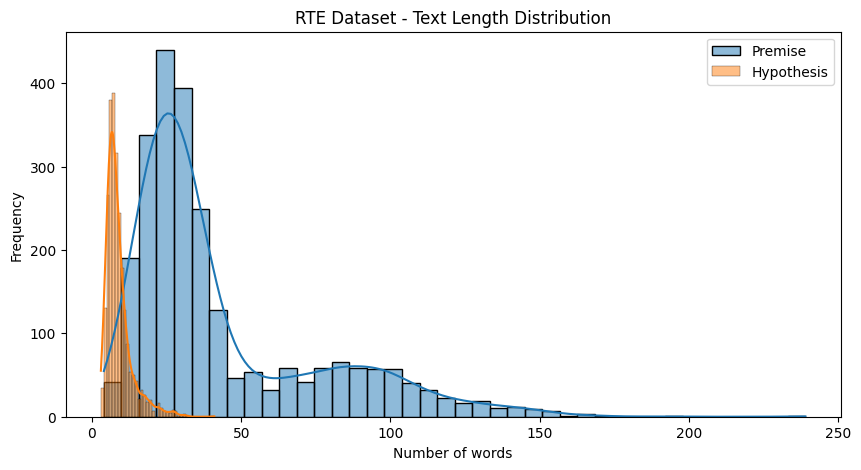

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate word counts
for df in [train_df, val_df]:
    df["premise_words"] = df["premise"].astype(str).apply(
        lambda x: len(x.split())
    )
    df["hypothesis_words"] = df["hypothesis"].astype(str).apply(
        lambda x: len(x.split())
    )

print("TRAINING TEXT LENGTH STATISTICS")
display(
    train_df[["premise_words", "hypothesis_words"]].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["premise_words"],
    bins=40,
    kde=True,
    label="Premise",
    alpha=0.5
)

sns.histplot(
    train_df["hypothesis_words"],
    bins=40,
    kde=True,
    label="Hypothesis",
    alpha=0.5
)

plt.title("RTE Dataset - Text Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [13]:
train_clean = train_df.copy()
val_clean = val_df.copy()

before = len(train_clean)

train_clean = train_clean.drop_duplicates(
    subset=["premise", "hypothesis"],
    keep="first"
).reset_index(drop=True)

after = len(train_clean)

print("DATA CLEANING SUMMARY")
print("=" * 45)
print("Original training samples:", before)
print("Duplicates removed:", before - after)
print("Final training samples:", after)
print("Validation samples:", len(val_clean))

assert train_clean.duplicated(
    subset=["premise", "hypothesis"]
).sum() == 0

print("\nDuplicate removal verified!")

DATA CLEANING SUMMARY
Original training samples: 2490
Duplicates removed: 2
Final training samples: 2488
Validation samples: 277

Duplicate removal verified!


In [14]:
from transformers import AutoTokenizer

MODEL_NAME = "microsoft/deberta-v3-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model input length:", tokenizer.model_max_length)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Tokenizer loaded successfully!
Model: microsoft/deberta-v3-base
Vocabulary size: 128000
Maximum model input length: 1000000000000000019884624838656


In [15]:
from tqdm.auto import tqdm

def get_token_lengths(df):
    lengths = []

    for premise, hypothesis in tqdm(
        zip(df["premise"], df["hypothesis"]),
        total=len(df)
    ):
        encoded = tokenizer(
            str(premise),
            str(hypothesis),
            truncation=False,
            add_special_tokens=True
        )

        lengths.append(len(encoded["input_ids"]))

    return lengths


train_clean["token_length"] = get_token_lengths(train_clean)
val_clean["token_length"] = get_token_lengths(val_clean)

print("TRAINING TOKEN LENGTH STATISTICS")
display(
    train_clean["token_length"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

print("\nVALIDATION TOKEN LENGTH STATISTICS")
display(
    val_clean["token_length"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

  0%|          | 0/2488 [00:00<?, ?it/s]

  0%|          | 0/277 [00:00<?, ?it/s]

TRAINING TOKEN LENGTH STATISTICS


count    2488.00
mean       67.35
std        39.58
min        13.00
50%        53.00
75%        81.00
90%       130.00
95%       150.00
99%       188.00
max       286.00
Name: token_length, dtype: float64


VALIDATION TOKEN LENGTH STATISTICS


count    277.00
mean      65.73
std       39.48
min       17.00
50%       51.00
75%       75.00
90%      129.40
95%      152.00
99%      185.72
max      243.00
Name: token_length, dtype: float64

In [16]:
candidate_lengths = [128, 160, 192, 224, 256, 320]

print("=" * 80)
print("SEQUENCE LENGTH COMPARISON")
print("=" * 80)

for max_len in candidate_lengths:

    train_truncated = (train_clean["token_length"] > max_len).sum()
    val_truncated = (val_clean["token_length"] > max_len).sum()

    train_pct = train_truncated / len(train_clean) * 100
    val_pct = val_truncated / len(val_clean) * 100

    print(
        f"MAX_LENGTH: {max_len:3d} | "
        f"Train truncated: {train_truncated:3d} ({train_pct:.2f}%) | "
        f"Validation truncated: {val_truncated:3d} ({val_pct:.2f}%)"
    )

SEQUENCE LENGTH COMPARISON
MAX_LENGTH: 128 | Train truncated: 261 (10.49%) | Validation truncated:  29 (10.47%)
MAX_LENGTH: 160 | Train truncated:  91 (3.66%) | Validation truncated:   8 (2.89%)
MAX_LENGTH: 192 | Train truncated:  21 (0.84%) | Validation truncated:   2 (0.72%)
MAX_LENGTH: 224 | Train truncated:   4 (0.16%) | Validation truncated:   1 (0.36%)
MAX_LENGTH: 256 | Train truncated:   1 (0.04%) | Validation truncated:   0 (0.00%)
MAX_LENGTH: 320 | Train truncated:   0 (0.00%) | Validation truncated:   0 (0.00%)


In [17]:
LABEL2ID = {
    "not_entailment": 0,
    "entailment": 1
}

ID2LABEL = {
    0: "not_entailment",
    1: "entailment"
}

MAX_LENGTH = 256

train_clean["label_id"] = train_clean["label"].map(LABEL2ID)
val_clean["label_id"] = val_clean["label"].map(LABEL2ID)

assert train_clean["label_id"].notna().all()
assert val_clean["label_id"].notna().all()

train_clean["label_id"] = train_clean["label_id"].astype(int)
val_clean["label_id"] = val_clean["label_id"].astype(int)

print("Label encoding completed!")
print(train_clean[["label", "label_id"]].head(10))
print("\nLabel mapping:", LABEL2ID)

Label encoding completed!
            label  label_id
0  not_entailment         0
1      entailment         1
2      entailment         1
3      entailment         1
4  not_entailment         0
5      entailment         1
6  not_entailment         0
7  not_entailment         0
8      entailment         1
9      entailment         1

Label mapping: {'not_entailment': 0, 'entailment': 1}


In [18]:
print("Tokenizing training dataset...")

train_encodings = tokenizer(
    train_clean["premise"].astype(str).tolist(),
    train_clean["hypothesis"].astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

print("Tokenizing validation dataset...")

val_encodings = tokenizer(
    val_clean["premise"].astype(str).tolist(),
    val_clean["hypothesis"].astype(str).tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

print("\nTOKENIZATION COMPLETED")
print("Training examples:", len(train_encodings["input_ids"]))
print("Validation examples:", len(val_encodings["input_ids"]))

print("\nFirst tokenized example:")
print(tokenizer.convert_ids_to_tokens(
    train_encodings["input_ids"][0][:30]
))

Tokenizing training dataset...
Tokenizing validation dataset...

TOKENIZATION COMPLETED
Training examples: 2488
Validation examples: 277

First tokenized example:
['[CLS]', '▁No', '▁Weapons', '▁of', '▁Mass', '▁Destruction', '▁Found', '▁in', '▁Iraq', '▁Yet', '.', '[SEP]', '▁Weapons', '▁of', '▁Mass', '▁Destruction', '▁Found', '▁in', '▁Iraq', '.', '[SEP]']


In [19]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding

class RTEDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx], dtype=torch.long)
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item


train_dataset = RTEDataset(
    train_encodings,
    train_clean["label_id"].tolist()
)

val_dataset = RTEDataset(
    val_encodings,
    val_clean["label_id"].tolist()
)

print("PyTorch datasets created!")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))

PyTorch datasets created!
Training: 2488
Validation: 277


In [20]:
from transformers import DataCollatorWithPadding

BATCH_SIZE = 16

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("DATALOADERS CONFIGURED")
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

DATALOADERS CONFIGURED
Batch size: 16
Training batches: 156
Validation batches: 18


In [21]:
batch = next(iter(train_loader))

print("BATCH VERIFICATION")
print("=" * 45)

for key, value in batch.items():
    print(f"{key}: {value.shape}")

print("\nLabels:", batch["labels"])
print("Input tensor type:", batch["input_ids"].dtype)

assert batch["input_ids"].shape[0] == BATCH_SIZE
assert batch["input_ids"].shape[1] <= MAX_LENGTH

print("\nBatch verification successful!")

BATCH VERIFICATION
input_ids: torch.Size([16, 173])
token_type_ids: torch.Size([16, 173])
attention_mask: torch.Size([16, 173])
labels: torch.Size([16])

Labels: tensor([0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0])
Input tensor type: torch.int64

Batch verification successful!


In [22]:
from transformers import AutoModelForSequenceClassification

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    label2id=LABEL2ID,
    id2label=ID2LABEL
)

model = model.to(device)

print("MODEL LOADED SUCCESSFULLY")
print("Architecture:", MODEL_NAME)
print("Device:", device)
print("Number of output classes:", model.config.num_labels)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

MODEL LOADED SUCCESSFULLY
Architecture: microsoft/deberta-v3-base
Device: cuda
Number of output classes: 2


model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

In [23]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = total_params - trainable_params

print("=" * 55)
print("DEBERTA-V3-BASE PARAMETER ANALYSIS")
print("=" * 55)

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")

print(f"\nTotal parameters (M)   : {total_params / 1e6:.2f}M")
print(f"Trainable params (M)   : {trainable_params / 1e6:.2f}M")

print("\nTraining strategy: Full fine-tuning")

DEBERTA-V3-BASE PARAMETER ANALYSIS
Total parameters       : 184,423,682
Trainable parameters   : 184,423,682
Non-trainable params   : 0

Total parameters (M)   : 184.42M
Trainable params (M)   : 184.42M

Training strategy: Full fine-tuning


In [24]:
import math
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
EPOCHS = 5
WARMUP_RATIO = 0.06

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_training_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_training_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("OPTIMIZER AND SCHEDULER CONFIGURED")
print("=" * 45)
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs:", EPOCHS)
print("Training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

OPTIMIZER AND SCHEDULER CONFIGURED
Optimizer: AdamW
Learning rate: 1e-05
Weight decay: 0.01
Epochs: 5
Training steps: 780
Warmup steps: 46


In [25]:
USE_AMP = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Mixed precision:", USE_AMP)
print("Precision:", "FP16" if USE_AMP else "FP32")

Mixed precision: True
Precision: FP16


In [26]:
import os

PROJECT_DIR = "/kaggle/working/RTE_Challenge"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
LOG_DIR = os.path.join(PROJECT_DIR, "logs")

for directory in [MODEL_DIR, RESULT_DIR, LOG_DIR]:
    os.makedirs(directory, exist_ok=True)

print("PROJECT DIRECTORIES CREATED")
print(PROJECT_DIR)

PROJECT DIRECTORIES CREATED
/kaggle/working/RTE_Challenge


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import json
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
def evaluate_model(model, val_loader):

    model.eval()

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in val_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(**batch)

            total_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch["labels"].cpu().numpy()
            )

    avg_loss = total_loss / len(val_loader)

    accuracy = accuracy_score(all_labels, all_predictions)

    precision = precision_score(
        all_labels, all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels, all_predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": macro_f1,
        "predictions": np.array(all_predictions),
        "labels": np.array(all_labels)
    }

In [ ]:
import copy

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "deberta_base_experiment1"
)

os.makedirs(BEST_MODEL_PATH, exist_ok=True)

history = []

best_f1 = -1.0
best_epoch = 0
patience = 2
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    print("\n" + "=" * 65)
    print(f"EXPERIMENT 1 - EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 65)

    model.train()

    epoch_loss = 0
    start_time = time.time()

    for step, batch in enumerate(train_loader):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        epoch_loss += loss.item()

        if (step + 1) % 25 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Batch {step + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    train_loss = epoch_loss / len(train_loader)

    # Validation
    val_metrics = evaluate_model(model, val_loader)

    epoch_time = time.time() - start_time

    result = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "accuracy": val_metrics["accuracy"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "macro_f1": val_metrics["macro_f1"],
        "epoch_time": epoch_time
    }

    history.append(result)

    print("\nEPOCH RESULTS")
    print("-" * 45)
    print(f"Training Loss : {train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Accuracy      : {val_metrics['accuracy'] * 100:.2f}%")
    print(f"Precision     : {val_metrics['precision'] * 100:.2f}%")
    print(f"Recall        : {val_metrics['recall'] * 100:.2f}%")
    print(f"Macro F1      : {val_metrics['macro_f1'] * 100:.2f}%")
    print(f"Time          : {epoch_time / 60:.2f} minutes")

    # Save best checkpoint
    if val_metrics["macro_f1"] > best_f1:

        best_f1 = val_metrics["macro_f1"]
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        model.save_pretrained(BEST_MODEL_PATH)
        tokenizer.save_pretrained(BEST_MODEL_PATH)

        print("\nBEST CHECKPOINT SAVED!")
        print("Best Macro F1:", round(best_f1 * 100, 2))

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered.")
        break

print("\n" + "=" * 65)
print("EXPERIMENT 1 COMPLETED")
print("=" * 65)
print("Best epoch:", best_epoch)
print("Best validation Macro F1:", round(best_f1 * 100, 2))
print("Saved at:", BEST_MODEL_PATH)

In [29]:
import copy

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "deberta_base_experiment1"
)

os.makedirs(BEST_MODEL_PATH, exist_ok=True)

history = []

best_f1 = -1.0
best_epoch = 0
patience = 2
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    print("\n" + "=" * 65)
    print(f"EXPERIMENT 1 - EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 65)

    model.train()

    epoch_loss = 0
    start_time = time.time()

    for step, batch in enumerate(train_loader):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        epoch_loss += loss.item()

        if (step + 1) % 25 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Batch {step + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    train_loss = epoch_loss / len(train_loader)

    # Validation
    val_metrics = evaluate_model(model, val_loader)

    epoch_time = time.time() - start_time

    result = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "accuracy": val_metrics["accuracy"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "macro_f1": val_metrics["macro_f1"],
        "epoch_time": epoch_time
    }

    history.append(result)

    print("\nEPOCH RESULTS")
    print("-" * 45)
    print(f"Training Loss : {train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Accuracy      : {val_metrics['accuracy'] * 100:.2f}%")
    print(f"Precision     : {val_metrics['precision'] * 100:.2f}%")
    print(f"Recall        : {val_metrics['recall'] * 100:.2f}%")
    print(f"Macro F1      : {val_metrics['macro_f1'] * 100:.2f}%")
    print(f"Time          : {epoch_time / 60:.2f} minutes")

    # Save best checkpoint
    if val_metrics["macro_f1"] > best_f1:

        best_f1 = val_metrics["macro_f1"]
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        model.save_pretrained(BEST_MODEL_PATH)
        tokenizer.save_pretrained(BEST_MODEL_PATH)

        print("\nBEST CHECKPOINT SAVED!")
        print("Best Macro F1:", round(best_f1 * 100, 2))

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered.")
        break

print("\n" + "=" * 65)
print("EXPERIMENT 1 COMPLETED")
print("=" * 65)
print("Best epoch:", best_epoch)
print("Best validation Macro F1:", round(best_f1 * 100, 2))
print("Saved at:", BEST_MODEL_PATH)


EXPERIMENT 1 - EPOCH 1/5


ValueError: Attempting to unscale FP16 gradients.

In [30]:
print("Model parameter dtype:", next(model.parameters()).dtype)
print("AMP enabled:", USE_AMP)
print("Device:", device)

Model parameter dtype: torch.float16
AMP enabled: True
Device: cuda


In [31]:
import gc
import torch

# Remove old model
del model
gc.collect()
torch.cuda.empty_cache()

# Load model explicitly in FP32
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    label2id=LABEL2ID,
    id2label=ID2LABEL,
    torch_dtype=torch.float32
)

model = model.to(device)

print("Parameter dtype:", next(model.parameters()).dtype)
print("GPU:", torch.cuda.get_device_name(0))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Parameter dtype: torch.float32
GPU: Tesla T4


In [32]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_training_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_training_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

USE_AMP = True

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

print("Optimizer recreated.")
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)
print("AMP enabled:", USE_AMP)

Optimizer recreated.
Total training steps: 780
Warmup steps: 46
AMP enabled: True


In [33]:
print(next(model.parameters()).dtype)
print(scaler.is_enabled())

torch.float32
True


In [37]:
import os

PROJECT_DIR = "/kaggle/working/RTE_Challenge"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
LOGS_DIR = os.path.join(PROJECT_DIR, "logs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(LOGS_DIR, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Checkpoint exists:", os.path.exists(BEST_MODEL_PATH))

Results directory: /kaggle/working/RTE_Challenge/results
Checkpoint exists: True


In [38]:

import os
import time
import torch
import pandas as pd



BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "deberta_base_experiment1"
)

os.makedirs(BEST_MODEL_PATH, exist_ok=True)

# Verify model and AMP configuration
assert next(model.parameters()).dtype == torch.float32, \
    "Model must use FP32 parameters."

assert scaler.is_enabled(), \
    "GradScaler must be enabled."

history = []

best_f1 = -1.0
best_epoch = 0

PATIENCE = 2
epochs_without_improvement = 0

print("=" * 65)
print("STARTING EXPERIMENT 1: DEBERTA-V3-BASE")
print("=" * 65)

for epoch in range(EPOCHS):

    print(f"\n{'=' * 65}")
    print(f"EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 65)

    model.train()

    total_train_loss = 0.0
    start_time = time.time()

    for step, batch in enumerate(train_loader):

        # Move batch to GPU
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision forward pass
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(**batch)
            loss = outputs.loss

        # Backpropagation
        scaler.scale(loss).backward()

        # Unscale gradients before clipping
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Optimizer and scaler update
        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        total_train_loss += loss.item()

        if (step + 1) % 25 == 0:
            print(
                f"Epoch {epoch + 1} | "
                f"Batch {step + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    # Average training loss
    train_loss = total_train_loss / len(train_loader)

    # ======================================
    # VALIDATION
    # ======================================

    val_metrics = evaluate_model(model, val_loader)

    epoch_time = time.time() - start_time

    result = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "accuracy": val_metrics["accuracy"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "macro_f1": val_metrics["macro_f1"],
        "epoch_time": epoch_time
    }

    history.append(result)

    # ======================================
    # PRINT RESULTS
    # ======================================

    print("\nEPOCH RESULTS")
    print("-" * 50)

    print(f"Training Loss   : {train_loss:.4f}")
    print(f"Validation Loss : {val_metrics['loss']:.4f}")

    print(f"Accuracy        : {val_metrics['accuracy'] * 100:.2f}%")
    print(f"Precision       : {val_metrics['precision'] * 100:.2f}%")
    print(f"Recall          : {val_metrics['recall'] * 100:.2f}%")
    print(f"Macro F1        : {val_metrics['macro_f1'] * 100:.2f}%")

    print(f"Epoch Time      : {epoch_time / 60:.2f} minutes")

    # ======================================
    # SAVE BEST MODEL
    # ======================================

    if val_metrics["macro_f1"] > best_f1:

        best_f1 = val_metrics["macro_f1"]
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        model.save_pretrained(BEST_MODEL_PATH)
        tokenizer.save_pretrained(BEST_MODEL_PATH)

        print("\nBEST MODEL CHECKPOINT SAVED!")
        print(f"Best Macro F1: {best_f1 * 100:.2f}%")

    else:

        epochs_without_improvement += 1

        print(
            f"\nNo improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    # Save training history after every epoch
    pd.DataFrame(history).to_csv(
        os.path.join(RESULTS_DIR, "experiment1_history.csv"),
        index=False
    )

    # ======================================
    # EARLY STOPPING
    # ======================================

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# ==========================================
# EXPERIMENT SUMMARY
# ==========================================

print("\n" + "=" * 65)
print("EXPERIMENT 1 COMPLETED")
print("=" * 65)

print("Best Epoch:", best_epoch)
print(f"Best Validation Macro F1: {best_f1 * 100:.2f}%")
print("Model saved at:", BEST_MODEL_PATH)

print("\nTRAINING HISTORY")

history_df = pd.DataFrame(history)
display(history_df.round(4))


STARTING EXPERIMENT 1: DEBERTA-V3-BASE

EPOCH 1/5
Epoch 1 | Batch 25/156 | Loss: 0.6108
Epoch 1 | Batch 50/156 | Loss: 0.6233
Epoch 1 | Batch 75/156 | Loss: 0.3868
Epoch 1 | Batch 100/156 | Loss: 0.4215
Epoch 1 | Batch 125/156 | Loss: 0.4478
Epoch 1 | Batch 150/156 | Loss: 0.3067

EPOCH RESULTS
--------------------------------------------------
Training Loss   : 0.4645
Validation Loss : 0.4189
Accuracy        : 81.23%
Precision       : 81.81%
Recall          : 80.82%
Macro F1        : 80.96%
Epoch Time      : 0.78 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


BEST MODEL CHECKPOINT SAVED!
Best Macro F1: 80.96%

EPOCH 2/5
Epoch 2 | Batch 25/156 | Loss: 0.4031
Epoch 2 | Batch 50/156 | Loss: 0.3715
Epoch 2 | Batch 75/156 | Loss: 0.0589
Epoch 2 | Batch 100/156 | Loss: 0.0458
Epoch 2 | Batch 125/156 | Loss: 0.1655
Epoch 2 | Batch 150/156 | Loss: 0.3696

EPOCH RESULTS
--------------------------------------------------
Training Loss   : 0.2151
Validation Loss : 0.4936
Accuracy        : 81.95%
Precision       : 82.31%
Recall          : 81.62%
Macro F1        : 81.75%
Epoch Time      : 0.75 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


BEST MODEL CHECKPOINT SAVED!
Best Macro F1: 81.75%

EPOCH 3/5
Epoch 3 | Batch 25/156 | Loss: 0.0580
Epoch 3 | Batch 50/156 | Loss: 0.0162
Epoch 3 | Batch 75/156 | Loss: 0.1658
Epoch 3 | Batch 100/156 | Loss: 0.1154
Epoch 3 | Batch 125/156 | Loss: 0.0169
Epoch 3 | Batch 150/156 | Loss: 0.2232

EPOCH RESULTS
--------------------------------------------------
Training Loss   : 0.1122
Validation Loss : 0.6888
Accuracy        : 80.87%
Precision       : 81.37%
Recall          : 80.48%
Macro F1        : 80.61%
Epoch Time      : 0.76 minutes

No improvement: 1/2

EPOCH 4/5
Epoch 4 | Batch 25/156 | Loss: 0.0112
Epoch 4 | Batch 50/156 | Loss: 0.0146
Epoch 4 | Batch 75/156 | Loss: 0.0951
Epoch 4 | Batch 100/156 | Loss: 0.0115
Epoch 4 | Batch 125/156 | Loss: 0.0035
Epoch 4 | Batch 150/156 | Loss: 0.0116

EPOCH RESULTS
--------------------------------------------------
Training Loss   : 0.0601
Validation Loss : 0.7889
Accuracy        : 81.23%
Precision       : 82.11%
Recall          : 80.74%
Macro

,epoch,train_loss,val_loss,accuracy,precision,recall,macro_f1,epoch_time
0,1,0.4645,0.4189,0.8123,0.8181,0.8082,0.8096,46.6898
1,2,0.2151,0.4936,0.8195,0.8231,0.8162,0.8175,45.2260
2,3,0.1122,0.6888,0.8087,0.8137,0.8048,0.8061,45.8139
3,4,0.0601,0.7889,0.8123,0.8211,0.8074,0.8089,45.3226


In [39]:
from transformers import AutoModelForSequenceClassification

BEST_MODEL_PATH = "/kaggle/working/RTE_Challenge/models/deberta_base_experiment1"

best_model = AutoModelForSequenceClassification.from_pretrained(
    BEST_MODEL_PATH
).to(device)

best_model.eval()

print("Best checkpoint loaded successfully.")
print("Model:", MODEL_NAME)
print("Parameters:", sum(p.numel() for p in best_model.parameters()))

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Best checkpoint loaded successfully.
Model: microsoft/deberta-v3-base
Parameters: 184423682


In [40]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

best_metrics = evaluate_model(best_model, val_loader)

y_true = best_metrics["labels"]
y_pred = best_metrics["predictions"]

print("=" * 60)
print("EXPERIMENT 1 - BEST CHECKPOINT")
print("=" * 60)

print(f"Accuracy  : {accuracy_score(y_true, y_pred) * 100:.2f}%")

print(f"Precision : {precision_score(y_true, y_pred, average='macro') * 100:.2f}%")

print(f"Recall    : {recall_score(y_true, y_pred, average='macro') * 100:.2f}%")

print(f"Macro F1  : {f1_score(y_true, y_pred, average='macro') * 100:.2f}%")

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Not Entailment", "Entailment"],
        digits=4
    )
)

EXPERIMENT 1 - BEST CHECKPOINT
Accuracy  : 81.95%
Precision : 82.31%
Recall    : 81.62%
Macro F1  : 81.75%

Classification Report:

                precision    recall  f1-score   support

Not Entailment     0.8462    0.7557    0.7984       131
    Entailment     0.8000    0.8767    0.8366       146

      accuracy                         0.8195       277
     macro avg     0.8231    0.8162    0.8175       277
  weighted avg     0.8218    0.8195    0.8185       277



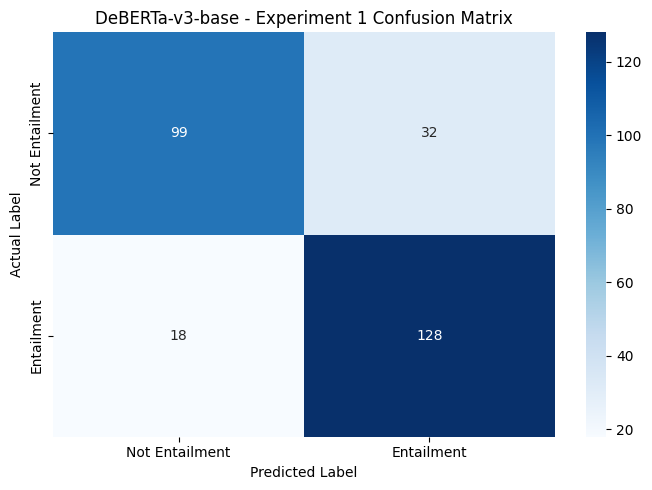

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Entailment", "Entailment"],
    yticklabels=["Not Entailment", "Entailment"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DeBERTa-v3-base - Experiment 1 Confusion Matrix")

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "experiment1_confusion_matrix.png"),
    dpi=300
)

plt.show()

In [42]:
import json

experiment1_summary = {
    "experiment": "Experiment 1",
    "architecture": "microsoft/deberta-v3-base",
    "parameters": sum(p.numel() for p in best_model.parameters()),
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "max_length": MAX_LENGTH,
    "best_epoch": best_epoch,
    "validation_samples": len(val_dataset),
    "accuracy": float(best_metrics["accuracy"]),
    "precision": float(best_metrics["precision"]),
    "recall": float(best_metrics["recall"]),
    "macro_f1": float(best_metrics["macro_f1"])
}

with open(
    os.path.join(RESULTS_DIR, "experiment1_summary.json"),
    "w"
) as f:
    json.dump(experiment1_summary, f, indent=4)

print("Experiment 1 summary saved.")
print("Results directory:", RESULTS_DIR)

Experiment 1 summary saved.
Results directory: /kaggle/working/RTE_Challenge/results


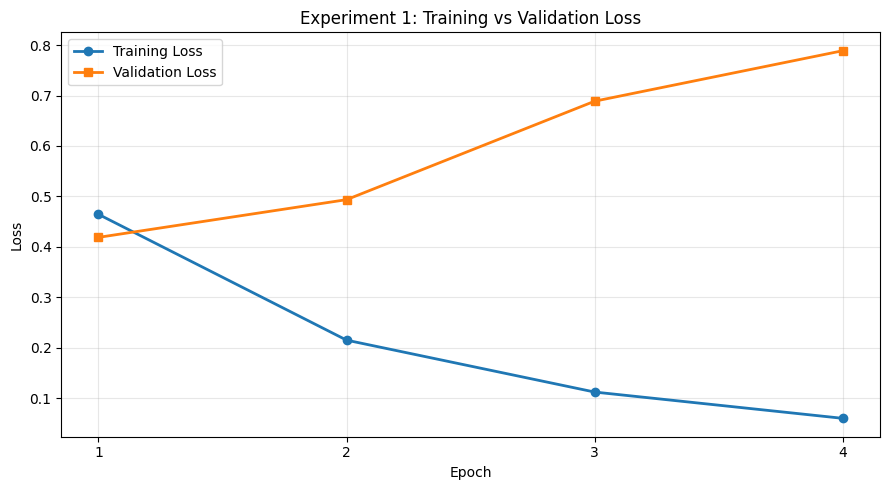

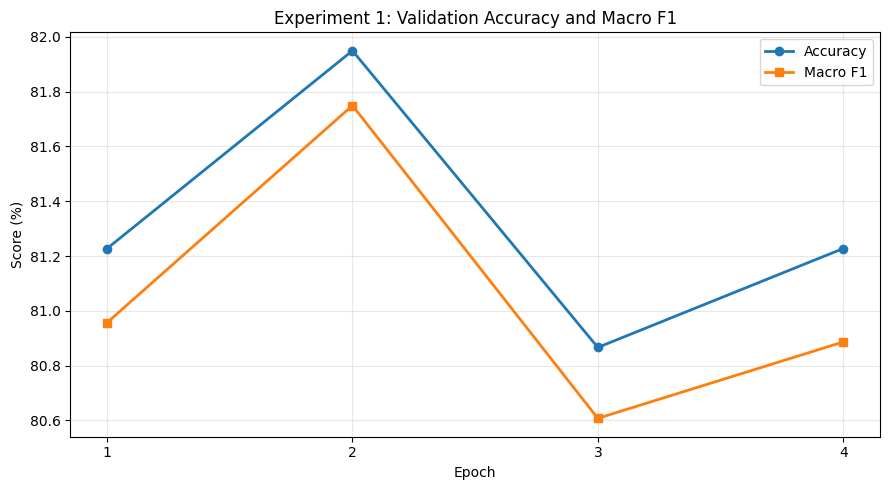

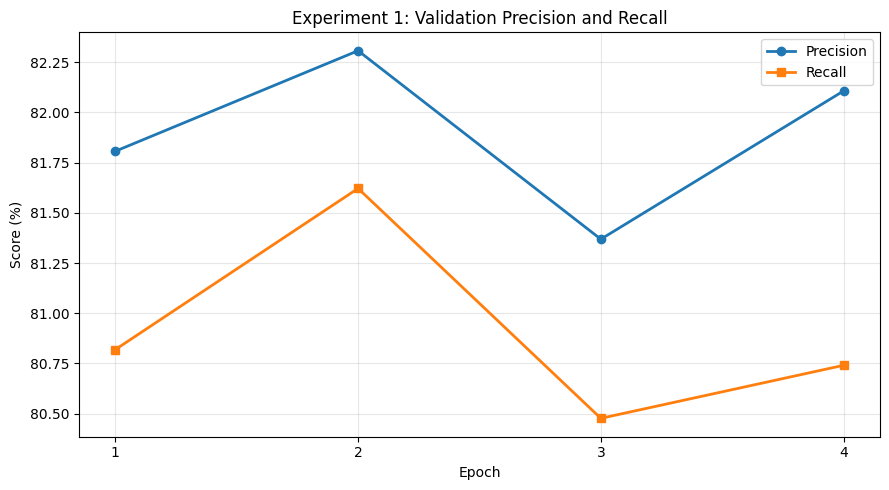

All three graphs saved successfully!
Location: /kaggle/working/RTE_Challenge/results


In [43]:

import matplotlib.pyplot as plt
import os

# Use the recorded training history
epochs = history_df["epoch"]

# 1. Training and validation loss
plt.figure(figsize=(9, 5))

plt.plot(epochs, history_df["train_loss"],
         marker="o", linewidth=2, label="Training Loss")

plt.plot(epochs, history_df["val_loss"],
         marker="s", linewidth=2, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 1: Training vs Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "experiment1_loss.png"),
    dpi=300
)
plt.show()


# 2. Validation Accuracy and Macro F1
plt.figure(figsize=(9, 5))

plt.plot(epochs, history_df["accuracy"] * 100,
         marker="o", linewidth=2, label="Accuracy")

plt.plot(epochs, history_df["macro_f1"] * 100,
         marker="s", linewidth=2, label="Macro F1")

plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Experiment 1: Validation Accuracy and Macro F1")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "experiment1_accuracy_f1.png"),
    dpi=300
)
plt.show()


# 3. Validation Precision and Recall
plt.figure(figsize=(9, 5))

plt.plot(epochs, history_df["precision"] * 100,
         marker="o", linewidth=2, label="Precision")

plt.plot(epochs, history_df["recall"] * 100,
         marker="s", linewidth=2, label="Recall")

plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Experiment 1: Validation Precision and Recall")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "experiment1_precision_recall.png"),
    dpi=300
)
plt.show()

print("All three graphs saved successfully!")
print("Location:", RESULTS_DIR)


In [44]:
import os
import shutil

PROJECT_DIR = "/kaggle/working/RTE_Challenge"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

# Include graphs, metrics and training history
files_to_include = [
    "experiment1_loss.png",
    "experiment1_accuracy_f1.png",
    "experiment1_precision_recall.png",
    "experiment1_confusion_matrix.png",
    "experiment1_history.csv",
    "experiment1_summary.json"
]

EXPORT_DIR = "/kaggle/working/Experiment1_Results"
os.makedirs(EXPORT_DIR, exist_ok=True)

for filename in files_to_include:
    source = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join(EXPORT_DIR, filename)
        )
        print("Copied:", filename)
    else:
        print("Not found:", filename)

ZIP_PATH = shutil.make_archive(
    "/kaggle/working/Experiment1_Results",
    "zip",
    EXPORT_DIR
)

print("\nZIP created:", ZIP_PATH)

Copied: experiment1_loss.png
Copied: experiment1_accuracy_f1.png
Copied: experiment1_precision_recall.png
Copied: experiment1_confusion_matrix.png
Copied: experiment1_history.csv
Copied: experiment1_summary.json

ZIP created: /kaggle/working/Experiment1_Results.zip


In [45]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/Experiment1_Results.zip"))

/kaggle/working/Experiment1_Results.zip

In [46]:
from IPython.display import FileLink, display
import os

zip_path = "/kaggle/working/Experiment1_Results.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    display(FileLink("Experiment1_Results.zip"))
else:
    print("ZIP file not found. Please recreate it.")

File exists: True


/kaggle/working/Experiment1_Results.zip

Experiment -2

In [47]:
!pip install -q optuna

In [48]:
import optuna
import gc
import json
import torch
import os
import numpy as np

from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.optim import AdamW

optuna.logging.set_verbosity(optuna.logging.INFO)

OPTUNA_DIR = os.path.join(
    PROJECT_DIR,
    "optuna_experiment"
)

os.makedirs(OPTUNA_DIR, exist_ok=True)

OPTUNA_EPOCHS = 3
N_TRIALS = 10

print("Optuna directory:", OPTUNA_DIR)
print("Number of trials:", N_TRIALS)
print("GPU:", torch.cuda.get_device_name(0))

Optuna directory: /kaggle/working/RTE_Challenge/optuna_experiment
Number of trials: 10
GPU: Tesla T4


In [49]:
def objective(trial):

    # ----------------------------------
    # Hyperparameters selected by Optuna
    # ----------------------------------

    learning_rate = trial.suggest_float(
        "learning_rate",
        5e-6,
        3e-5,
        log=True
    )

    weight_decay = trial.suggest_float(
        "weight_decay",
        0.0,
        0.1
    )

    warmup_ratio = trial.suggest_float(
        "warmup_ratio",
        0.03,
        0.12
    )

    batch_size = 16

    # ----------------------------------
    # Create fresh model
    # ----------------------------------

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        label2id=LABEL2ID,
        id2label=ID2LABEL,
        torch_dtype=torch.float32
    ).to(device)

    # ----------------------------------
    #  data loaders
    # ----------------------------------

    trial_train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=data_collator,
        num_workers=2,
        pin_memory=True
    )

    trial_val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=data_collator,
        num_workers=2,
        pin_memory=True
    )

    # ----------------------------------
    # Optimizer and scheduler
    # ----------------------------------

    optimizer = AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    total_steps = len(trial_train_loader) * OPTUNA_EPOCHS
    warmup_steps = int(total_steps * warmup_ratio)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=True
    )

    best_trial_f1 = 0.0

    # ----------------------------------
    # Training
    # ----------------------------------

    for epoch in range(OPTUNA_EPOCHS):

        model.train()

        for batch in trial_train_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(**batch)
                loss = outputs.loss

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            scheduler.step()

        # ----------------------------------
        # Validation
        # ----------------------------------

        metrics = evaluate_model(
            model,
            trial_val_loader
        )

        macro_f1 = metrics["macro_f1"]

        best_trial_f1 = max(
            best_trial_f1,
            macro_f1
        )

        trial.report(macro_f1, epoch)

        print(
            f"Trial {trial.number} | "
            f"Epoch {epoch + 1} | "
            f"Accuracy: {metrics['accuracy'] * 100:.2f}% | "
            f"Macro F1: {macro_f1 * 100:.2f}%"
        )

        # Allow Optuna to stop weak trials
        if trial.should_prune():
            raise optuna.TrialPruned()

    # ----------------------------------
    # Cleanup
    # ----------------------------------

    del model
    del optimizer
    del scheduler
    del scaler
    del trial_train_loader
    del trial_val_loader

    gc.collect()
    torch.cuda.empty_cache()

    return best_trial_f1

In [50]:
study = optuna.create_study(
    study_name="DeBERTa_v3_base_RTE",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=3,
        n_warmup_steps=1
    )
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    gc_after_trial=True
)

print("\n" + "=" * 60)
print("OPTUNA OPTIMIZATION COMPLETED")
print("=" * 60)

print("Best Macro F1:", round(study.best_value * 100, 2), "%")
print("Best Hyperparameters:")

for key, value in study.best_params.items():
    print(f"{key}: {value}")

[I 2026-11-15 10:38:02,463] A new study created in memory with name: DeBERTa_v3_base_RTE


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Trial 0 | Epoch 1 | Accuracy: 69.68% | Macro F1: 69.66%
Trial 0 | Epoch 2 | Accuracy: 73.65% | Macro F1: 72.44%
Trial 0 | Epoch 3 | Accuracy: 75.45% | Macro F1: 74.90%


[I 2026-11-15 10:40:21,143] Trial 0 finished with value: 0.7490139643961198 and parameters: {'learning_rate': 9.781801964118497e-06, 'weight_decay': 0.09507143064099162, 'warmup_ratio': 0.09587945476302645}. Best is trial 0 with value: 0.7490139643961198.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

... (36 outputs left out)

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Trial 9 | Epoch 1 | Accuracy: 66.79% | Macro F1: 65.89%


[I 2026-11-15 10:57:16,687] Trial 9 pruned. 


Trial 9 | Epoch 2 | Accuracy: 74.37% | Macro F1: 73.70%

OPTUNA OPTIMIZATION COMPLETED
Best Macro F1: 82.88 %
Best Hyperparameters:
learning_rate: 1.7781056670396774e-05
weight_decay: 0.0020584494295802446
warmup_ratio: 0.11729188669457949


In [ ]:
import matplotlib.pyplot as plt
import optuna

# Load your existing Optuna study
# If study is already available in memory, skip this line.
# study = optuna.load_study(
#     study_name="your_study_name",
#     storage="sqlite:///optuna_study.db"
# )

# Extract trial information
trials = study.trials

trial_numbers = []
accuracies = []

for trial in trials:
    if trial.value is not None:
        trial_numbers.append(trial.number + 1)
        accuracies.append(trial.value * 100)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    trial_numbers,
    accuracies,
    marker='o',
    linewidth=2,
    label='Trial Accuracy'
)

# Best accuracy so far
best_accuracy = []
current_best = 0

for acc in accuracies:
    current_best = max(current_best, acc)
    best_accuracy.append(current_best)

plt.plot(
    trial_numbers,
    best_accuracy,
    linestyle='--',
    linewidth=2,
    label='Best Accuracy So Far'
)

plt.xlabel("Optuna Trial")
plt.ylabel("Validation Accuracy (%)")
plt.title("Experiment 2: Optuna Hyperparameter Optimization")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "/kaggle/working/RTE_Challenge/experiment2_optuna_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Total trials: {len(trial_numbers)}")
print(f"Best accuracy: {max(accuracies):.2f}%")

In [51]:
import os

EXPERIMENT2_DIR = "/kaggle/working/RTE_Challenge/experiment2_optuna"
EXPERIMENT2_MODEL_DIR = os.path.join(EXPERIMENT2_DIR, "best_model")
EXPERIMENT2_RESULTS_DIR = os.path.join(EXPERIMENT2_DIR, "results")
EXPERIMENT2_LOGS_DIR = os.path.join(EXPERIMENT2_DIR, "logs")

for path in [
    EXPERIMENT2_MODEL_DIR,
    EXPERIMENT2_RESULTS_DIR,
    EXPERIMENT2_LOGS_DIR
]:
    os.makedirs(path, exist_ok=True)

print("Experiment 2 directories created successfully.")
print(EXPERIMENT2_DIR)

Experiment 2 directories created successfully.
/kaggle/working/RTE_Challenge/experiment2_optuna


In [52]:
# ============================================
# EXPERIMENT 2: OPTUNA BEST CONFIGURATION
# ============================================

LEARNING_RATE = 1.7781056670396774e-05
WEIGHT_DECAY = 0.0020584494295802446
WARMUP_RATIO = 0.11729188669457949

BATCH_SIZE = 16
MAX_LENGTH = 256
EPOCHS = 8
PATIENCE = 2

BEST_MODEL_PATH = EXPERIMENT2_MODEL_DIR

print("EXPERIMENT 2 CONFIGURATION")
print("=" * 50)
print("Architecture       : DeBERTa-v3-base")
print("Parameters         : 184,423,682")
print("Learning rate      :", LEARNING_RATE)
print("Weight decay       :", WEIGHT_DECAY)
print("Warmup ratio       :", WARMUP_RATIO)
print("Batch size         :", BATCH_SIZE)
print("Maximum epochs     :", EPOCHS)
print("Early stopping     :", PATIENCE)
print("Model save path    :", BEST_MODEL_PATH)

EXPERIMENT 2 CONFIGURATION
Architecture       : DeBERTa-v3-base
Parameters         : 184,423,682
Learning rate      : 1.7781056670396774e-05
Weight decay       : 0.0020584494295802446
Warmup ratio       : 0.11729188669457949
Batch size         : 16
Maximum epochs     : 8
Early stopping     : 2
Model save path    : /kaggle/working/RTE_Challenge/experiment2_optuna/best_model


In [53]:
import torch
import gc
from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

# Clear previous model from GPU memory, if present
if "model" in globals():
    del model

if "best_model" in globals():
    del best_model

gc.collect()
torch.cuda.empty_cache()

# Load fresh model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    label2id=LABEL2ID,
    id2label=ID2LABEL,
    torch_dtype=torch.float32
).to(device)

print("Fresh Experiment 2 model loaded.")
print("Device:", device)
print("Parameter dtype:", next(model.parameters()).dtype)
print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Fresh Experiment 2 model loaded.
Device: cuda
Parameter dtype: torch.float32
Total parameters: 184423682


In [54]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Fresh optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Training steps
total_training_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_training_steps * WARMUP_RATIO)

# Learning-rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

# Mixed precision
USE_AMP = True
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("EXPERIMENT 2 OPTIMIZER AND SCHEDULER")
print("=" * 50)
print("Optimizer          : AdamW")
print("Learning rate      :", LEARNING_RATE)
print("Weight decay       :", WEIGHT_DECAY)
print("Total train batches:", len(train_loader))
print("Total train steps  :", total_training_steps)
print("Warmup steps       :", warmup_steps)
print("AMP enabled        :", USE_AMP)
print("GradScaler enabled :", scaler.is_enabled())

EXPERIMENT 2 OPTIMIZER AND SCHEDULER
Optimizer          : AdamW
Learning rate      : 1.7781056670396774e-05
Weight decay       : 0.0020584494295802446
Total train batches: 156
Total train steps  : 1248
Warmup steps       : 146
AMP enabled        : True
GradScaler enabled : True


In [55]:
# ============================================
# EXPERIMENT 2: TRAINING TRACKING
# ============================================

history_exp2 = []

best_val_f1_exp2 = 0.0
best_epoch_exp2 = 0
epochs_without_improvement = 0

for filename in [
    "experiment2_training_history.csv",
    "experiment2_best_metrics.json"
]:
    path = os.path.join(EXPERIMENT2_RESULTS_DIR, filename)
    if os.path.exists(path):
        print("Warning: Existing result file:", path)

print("Experiment 2 tracking initialized.")
print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Best checkpoint:", BEST_MODEL_PATH)

Experiment 2 tracking initialized.
Maximum epochs: 8
Early stopping patience: 2
Best checkpoint: /kaggle/working/RTE_Challenge/experiment2_optuna/best_model


In [56]:
import os
import gc
import json
import pandas as pd
import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Experiment 2 | Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress_bar:

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_train_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation
    val_metrics = evaluate_model(model, val_loader)

    val_loss = val_metrics["loss"]
    val_accuracy = val_metrics["accuracy"]
    val_precision = val_metrics["precision"]
    val_recall = val_metrics["recall"]
    val_f1 = val_metrics["macro_f1"]

    # Store epoch results
    epoch_result = {
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": val_loss,
        "accuracy": val_accuracy,
        "precision": val_precision,
        "recall": val_recall,
        "macro_f1": val_f1
    }

    history_exp2.append(epoch_result)

    print("\n" + "=" * 60)
    print(f"EXPERIMENT 2 - EPOCH {epoch + 1}/{EPOCHS}")
    print("=" * 60)
    print(f"Training Loss : {avg_train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Accuracy      : {val_accuracy * 100:.2f}%")
    print(f"Precision     : {val_precision * 100:.2f}%")
    print(f"Recall        : {val_recall * 100:.2f}%")
    print(f"Macro F1      : {val_f1 * 100:.2f}%")

    # Save best checkpoint
    if val_f1 > best_val_f1_exp2:

        best_val_f1_exp2 = val_f1
        best_epoch_exp2 = epoch + 1
        epochs_without_improvement = 0

        model.save_pretrained(BEST_MODEL_PATH)
        tokenizer.save_pretrained(BEST_MODEL_PATH)

        best_metrics_exp2 = {
            "best_epoch": best_epoch_exp2,
            "accuracy": val_accuracy,
            "precision": val_precision,
            "recall": val_recall,
            "macro_f1": val_f1,
            "validation_loss": val_loss
        }

        with open(
            os.path.join(
                EXPERIMENT2_RESULTS_DIR,
                "experiment2_best_metrics.json"
            ),
            "w"
        ) as f:
            json.dump(best_metrics_exp2, f, indent=4)

        print("Best model checkpoint saved.")

    else:
        epochs_without_improvement += 1
        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    # Save history after every epoch
    pd.DataFrame(history_exp2).to_csv(
        os.path.join(
            EXPERIMENT2_RESULTS_DIR,
            "experiment2_training_history.csv"
        ),
        index=False
    )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\n" + "=" * 60)
print("EXPERIMENT 2 TRAINING COMPLETED")
print("=" * 60)
print("Best Epoch:", best_epoch_exp2)
print(f"Best Validation Macro F1: {best_val_f1_exp2 * 100:.2f}%")
print(f"Best Model Path: {BEST_MODEL_PATH}")

Experiment 2 | Epoch 1/8:   0%|          | 0/156 [00:00<?, ?it/s]


EXPERIMENT 2 - EPOCH 1/8
Training Loss : 0.6795
Validation Loss: 0.5596
Accuracy      : 70.76%
Precision     : 70.77%
Recall        : 70.46%
Macro F1      : 70.50%


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model checkpoint saved.


Experiment 2 | Epoch 2/8:   0%|          | 0/156 [00:00<?, ?it/s]


EXPERIMENT 2 - EPOCH 2/8
Training Loss : 0.4787
Validation Loss: 0.4454
Accuracy      : 80.14%
Precision     : 80.09%
Recall        : 80.14%
Macro F1      : 80.11%


... (8 outputs left out)

Experiment 2 | Epoch 5/8:   0%|          | 0/156 [00:00<?, ?it/s]


EXPERIMENT 2 - EPOCH 5/8
Training Loss : 0.0774
Validation Loss: 0.8966
Accuracy      : 81.95%
Precision     : 82.12%
Recall        : 81.70%
Macro F1      : 81.80%
No improvement: 1/2


Experiment 2 | Epoch 6/8:   0%|          | 0/156 [00:00<?, ?it/s]


EXPERIMENT 2 - EPOCH 6/8
Training Loss : 0.0367
Validation Loss: 1.0557
Accuracy      : 82.31%
Precision     : 82.45%
Recall        : 82.08%
Macro F1      : 82.18%
No improvement: 2/2

Early stopping triggered.

EXPERIMENT 2 TRAINING COMPLETED
Best Epoch: 4
Best Validation Macro F1: 84.73%
Best Model Path: /kaggle/working/RTE_Challenge/experiment2_optuna/best_model


In [57]:
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Load best Experiment 2 checkpoint
best_model_exp2 = AutoModelForSequenceClassification.from_pretrained(
    BEST_MODEL_PATH
).to(device)

best_model_exp2.eval()

# Evaluate the saved checkpoint
best_metrics_exp2 = evaluate_model(best_model_exp2, val_loader)

print("=" * 60)
print("EXPERIMENT 2 - BEST CHECKPOINT VERIFICATION")
print("=" * 60)

print(f"Accuracy  : {best_metrics_exp2['accuracy']*100:.2f}%")
print(f"Precision : {best_metrics_exp2['precision']*100:.2f}%")
print(f"Recall    : {best_metrics_exp2['recall']*100:.2f}%")
print(f"Macro F1  : {best_metrics_exp2['macro_f1']*100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    best_metrics_exp2["labels"],
    best_metrics_exp2["predictions"],
    target_names=["Not Entailment", "Entailment"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    best_metrics_exp2["labels"],
    best_metrics_exp2["predictions"]
))

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

EXPERIMENT 2 - BEST CHECKPOINT VERIFICATION
Accuracy  : 84.84%
Precision : 84.97%
Recall    : 84.64%
Macro F1  : 84.73%

Classification Report:

                precision    recall  f1-score   support

Not Entailment     0.8618    0.8092    0.8346       131
    Entailment     0.8377    0.8836    0.8600       146

      accuracy                         0.8484       277
     macro avg     0.8497    0.8464    0.8473       277
  weighted avg     0.8491    0.8484    0.8480       277

Confusion Matrix:
[[106  25]
 [ 17 129]]


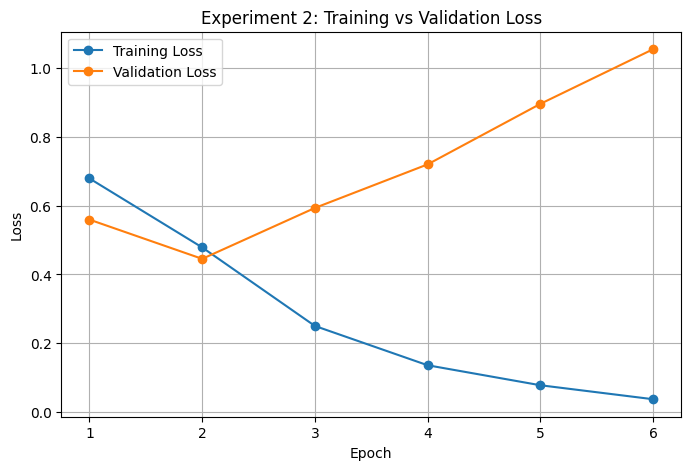

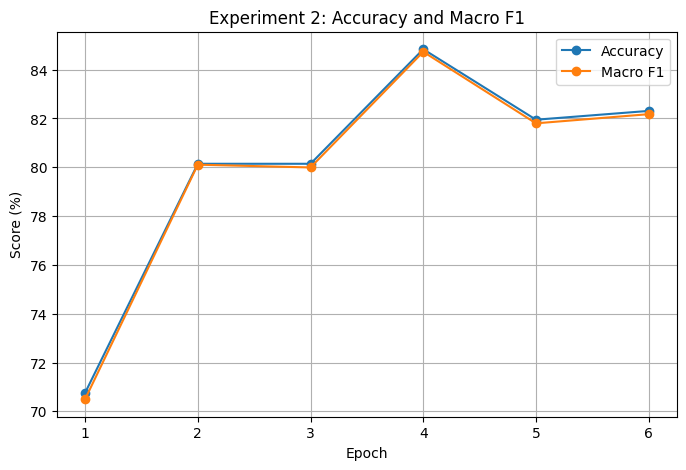

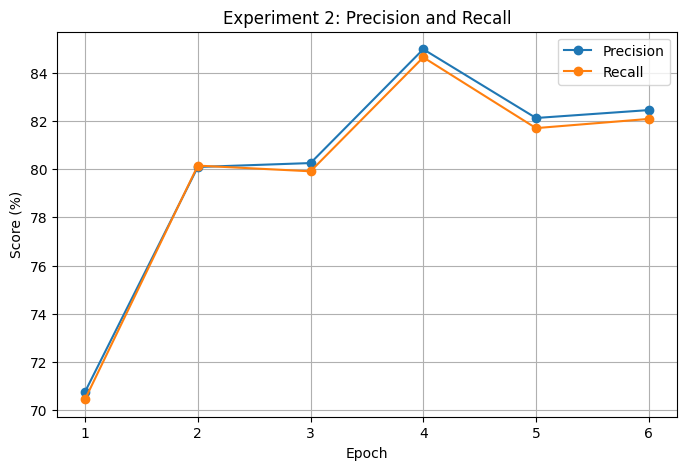

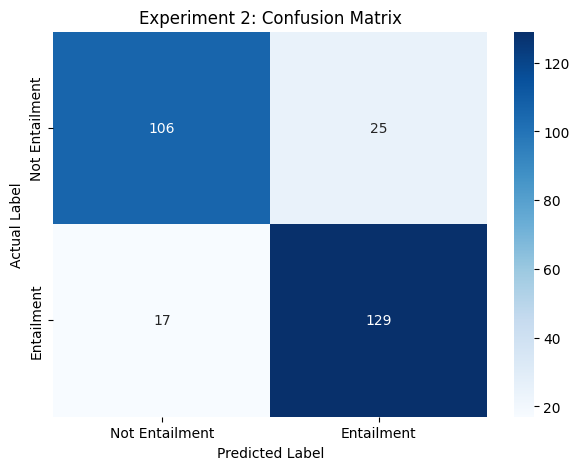

All 4 graphs saved successfully.
Results directory: /kaggle/working/RTE_Challenge/experiment2_optuna/results


In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
from sklearn.metrics import confusion_matrix

# Load experiment history
history_exp2_df = pd.DataFrame(history_exp2)

# Graph 1: Training and Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history_exp2_df["epoch"], history_exp2_df["train_loss"],
         marker="o", label="Training Loss")
plt.plot(history_exp2_df["epoch"], history_exp2_df["val_loss"],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 2: Training vs Validation Loss")
plt.xticks(history_exp2_df["epoch"])
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(EXPERIMENT2_RESULTS_DIR, "exp2_loss.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# Graph 2: Accuracy and Macro F1
plt.figure(figsize=(8, 5))
plt.plot(history_exp2_df["epoch"], history_exp2_df["accuracy"] * 100,
         marker="o", label="Accuracy")
plt.plot(history_exp2_df["epoch"], history_exp2_df["macro_f1"] * 100,
         marker="o", label="Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Experiment 2: Accuracy and Macro F1")
plt.xticks(history_exp2_df["epoch"])
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(EXPERIMENT2_RESULTS_DIR, "exp2_accuracy_f1.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# Graph 3: Precision and Recall
plt.figure(figsize=(8, 5))
plt.plot(history_exp2_df["epoch"], history_exp2_df["precision"] * 100,
         marker="o", label="Precision")
plt.plot(history_exp2_df["epoch"], history_exp2_df["recall"] * 100,
         marker="o", label="Recall")
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Experiment 2: Precision and Recall")
plt.xticks(history_exp2_df["epoch"])
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(EXPERIMENT2_RESULTS_DIR, "exp2_precision_recall.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# Graph 4: Confusion Matrix
cm = confusion_matrix(
    best_metrics_exp2["labels"],
    best_metrics_exp2["predictions"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Entailment", "Entailment"],
    yticklabels=["Not Entailment", "Entailment"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Experiment 2: Confusion Matrix")
plt.savefig(os.path.join(EXPERIMENT2_RESULTS_DIR, "exp2_confusion_matrix.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# Save history
history_exp2_df.to_csv(
    os.path.join(EXPERIMENT2_RESULTS_DIR, "experiment2_history.csv"),
    index=False
)

print("All 4 graphs saved successfully.")
print("Results directory:", EXPERIMENT2_RESULTS_DIR)

In [59]:
import shutil
import os
from IPython.display import FileLink, display

# Create ZIP archive
SOURCE_DIR = "/kaggle/working/RTE_Challenge/experiment2_optuna"
ZIP_PATH = "/kaggle/working/Experiment2_Optuna_Results"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    root_dir=SOURCE_DIR
)

FINAL_ZIP = ZIP_PATH + ".zip"

print("Experiment 2 saved successfully!")
print("File size:", round(os.path.getsize(FINAL_ZIP) / (1024**2), 2), "MB")

display(FileLink("Experiment2_Optuna_Results.zip"))

Experiment 2 saved successfully!
File size: 547.89 MB


/kaggle/working/Experiment2_Optuna_Results.zip

In [60]:

# STEP 1: Installing  and inspect LoRA support

!pip install -q peft

import torch
import transformers
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)

from transformers import AutoModelForSequenceClassification

MODEL_NAME = "microsoft/deberta-v3-base"

base_model_lora = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    label2id=LABEL2ID,
    id2label=ID2LABEL
)

print("\nMODEL ATTENTION LAYER NAMES")
print("=" * 50)

for name, module in base_model_lora.named_modules():
    if any(x in name for x in [
        "query_proj", "key_proj", "value_proj", "dense"
    ]):
        if isinstance(module, torch.nn.Linear):
            print(name, module.in_features, "->", module.out_features)

print("\nCLASSIFICATION HEAD")
print(base_model_lora.classifier)

print("\nPOOLER")
print(base_model_lora.pooler)


PyTorch: 2.11.0+cu130
Transformers: 5.20.2
PEFT: 0.21.2


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den


MODEL ATTENTION LAYER NAMES
deberta.encoder.layer.0.attention.self.query_proj 768 -> 768
deberta.encoder.layer.0.attention.self.key_proj 768 -> 768
deberta.encoder.layer.0.attention.self.value_proj 768 -> 768
deberta.encoder.layer.0.attention.output.dense 768 -> 768
deberta.encoder.layer.0.intermediate.dense 768 -> 3072
deberta.encoder.layer.0.output.dense 3072 -> 768
deberta.encoder.layer.1.attention.self.query_proj 768 -> 768
deberta.encoder.layer.1.attention.self.key_proj 768 -> 768
deberta.encoder.layer.1.attention.self.value_proj 768 -> 768
deberta.encoder.layer.1.attention.output.dense 768 -> 768
deberta.encoder.layer.1.intermediate.dense 768 -> 3072
deberta.encoder.layer.1.output.dense 3072 -> 768
deberta.encoder.layer.2.attention.self.query_proj 768 -> 768
deberta.encoder.layer.2.attention.self.key_proj 768 -> 768
deberta.encoder.layer.2.attention.self.value_proj 768 -> 768
deberta.encoder.layer.2.attention.output.dense 768 -> 768
deberta.encoder.layer.2.intermediate.dense 768

In [62]:

!pip uninstall -y torchao


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [63]:

import torch
import transformers
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)

try:
    import torchao
    print("TorchAO is still installed")
except ImportError:
    print("TorchAO is not installed - OK")


PyTorch: 2.11.0+cu130
Transformers: 5.20.2
PEFT: 0.21.2
TorchAO is not installed - OK


In [64]:

from transformers import AutoModelForSequenceClassification
from peft import LoraConfig, TaskType, get_peft_model
import torch

MODEL_NAME = "microsoft/deberta-v3-base"

# Load a fresh DeBERTa-v3-base model
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "not_entailment", 1: "entailment"},
    label2id={"not_entailment": 0, "entailment": 1}
)

# Configure LoRA
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=[
        "query_proj",
        "key_proj",
        "value_proj"
    ],
    modules_to_save=["pooler", "classifier"],
    bias="none"
)

# Attach LoRA adapters
model_lora = get_peft_model(base_model, lora_config)

model_lora = model_lora.to(device)

# Display parameter statistics
total_params = sum(p.numel() for p in model_lora.parameters())
trainable_params = sum(
    p.numel() for p in model_lora.parameters() if p.requires_grad
)

print("=" * 55)
print("DEBERTA-V3-BASE + LoRA PARAMETER ANALYSIS")
print("=" * 55)
print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")
print(f"Frozen parameters     : {total_params - trainable_params:,}")
print(f"Trainable percentage  : {100 * trainable_params / total_params:.4f}%")

print("\nLoRA configuration:")
print(lora_config)

print("\nTrainable parameter details:")
model_lora.print_trainable_parameters()


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

DEBERTA-V3-BASE + LoRA PARAMETER ANALYSIS
Total parameters      : 185,458,180
Trainable parameters  : 1,034,498
Frozen parameters     : 184,423,682
Trainable percentage  : 0.5578%

LoRA configuration:
LoraConfig(task_type=<TaskType.SEQ_CLS: 'SEQ_CLS'>, peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.2', base_model_name_or_path='microsoft/deberta-v3-base', revision=None, inference_mode=False, r=8, target_modules={'query_proj', 'value_proj', 'key_proj'}, exclude_modules=None, lora_alpha=16, lora_dropout=0.1, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=['pooler', 'classifier', 'classifier', 'score'], init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False

In [66]:

from collections import Counter

print("Parameter data types:")
print(Counter(str(p.dtype) for p in model_lora.parameters()))

print("\nTrainable parameter data types:")
print(Counter(
    str(p.dtype)
    for p in model_lora.parameters()
    if p.requires_grad
))


Parameter data types:
Counter({'torch.float16': 206, 'torch.float32': 72})

Trainable parameter data types:
Counter({'torch.float32': 72, 'torch.float16': 4})


In [67]:

# Keep all trainable parameters in FP32
for name, param in model_lora.named_parameters():
    if param.requires_grad:
        param.data = param.data.float()

print("Trainable parameter precision corrected.")

print(Counter(
    str(p.dtype)
    for p in model_lora.parameters()
    if p.requires_grad
))


Trainable parameter precision corrected.
Counter({'torch.float32': 76})


In [68]:

from transformers import get_linear_schedule_with_warmup

optimizer = torch.optim.AdamW(
    [p for p in model_lora.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader) * MAX_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Optimizer, scheduler and scaler reinitialized.")


Optimizer, scheduler and scaler reinitialized.


In [69]:

import os
import json
import torch
import pandas as pd
from transformers import get_linear_schedule_with_warmup

# ============================================
# 1. CONFIGURATION
# ============================================

EXP3_DIR = "/kaggle/working/RTE_Challenge/experiment3_lora"
EXP3_MODEL_DIR = os.path.join(EXP3_DIR, "best_model")
EXP3_RESULTS_DIR = os.path.join(EXP3_DIR, "results")

os.makedirs(EXP3_MODEL_DIR, exist_ok=True)
os.makedirs(EXP3_RESULTS_DIR, exist_ok=True)

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
MAX_EPOCHS = 8
PATIENCE = 2
USE_AMP = torch.cuda.is_available()

# ============================================
# 2. ENSURE TRAINABLE PARAMETERS ARE FP32
# ============================================

for name, param in model_lora.named_parameters():
    if param.requires_grad:
        param.data = param.data.float()

trainable_params = [
    p for p in model_lora.parameters() if p.requires_grad
]

assert all(p.dtype == torch.float32 for p in trainable_params), \
    "Some trainable parameters are not FP32!"

print("Trainable parameters verified as FP32.")

# ============================================
# 3. OPTIMIZER AND SCHEDULER
# ============================================

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader) * MAX_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ============================================
# 4. TRAINING INFORMATION
# ============================================

print("\n" + "=" * 60)
print("EXPERIMENT 3: DEBERTA-V3-BASE + LoRA")
print("=" * 60)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", 16)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("AMP enabled:", USE_AMP)
print("Trainable parameters:",
      sum(p.numel() for p in trainable_params))

# ============================================
# 5. TRAINING LOOP
# ============================================

history_exp3 = []

best_val_f1_exp3 = -1.0
best_epoch_exp3 = 0
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):

    model_lora.train()
    total_train_loss = 0.0

    for step, batch in enumerate(train_loader):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision forward pass
        with torch.amp.autocast(
            "cuda",
            enabled=USE_AMP
        ):
            outputs = model_lora(**batch)
            loss = outputs.loss

        # Backpropagation
        scaler.scale(loss).backward()

        # Unscale before gradient clipping
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # ========================================
    # VALIDATION
    # ========================================

    val_metrics = evaluate_model(model_lora, val_loader)

    val_loss = val_metrics["loss"]
    val_accuracy = val_metrics["accuracy"]
    val_precision = val_metrics["precision"]
    val_recall = val_metrics["recall"]
    val_f1 = val_metrics["macro_f1"]

    print("\n" + "=" * 60)
    print(f"EXPERIMENT 3 - EPOCH {epoch + 1}/{MAX_EPOCHS}")
    print("=" * 60)

    print(f"Train Loss : {avg_train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Accuracy   : {val_accuracy * 100:.2f}%")
    print(f"Precision  : {val_precision * 100:.2f}%")
    print(f"Recall     : {val_recall * 100:.2f}%")
    print(f"Macro F1   : {val_f1 * 100:.2f}%")

    history_exp3.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": val_loss,
        "accuracy": val_accuracy,
        "precision": val_precision,
        "recall": val_recall,
        "macro_f1": val_f1
    })

    # ========================================
    # SAVE BEST CHECKPOINT
    # ========================================

    if val_f1 > best_val_f1_exp3:

        best_val_f1_exp3 = val_f1
        best_epoch_exp3 = epoch + 1
        epochs_without_improvement = 0

        model_lora.save_pretrained(EXP3_MODEL_DIR)
        tokenizer.save_pretrained(EXP3_MODEL_DIR)

        best_metrics_to_save = {
            "experiment": "DeBERTa-v3-base + LoRA",
            "best_epoch": best_epoch_exp3,
            "accuracy": val_accuracy,
            "precision": val_precision,
            "recall": val_recall,
            "macro_f1": val_f1,
            "val_loss": val_loss,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "warmup_ratio": WARMUP_RATIO,
            "batch_size": 16,
            "max_length": 256,
            "lora_rank": 8,
            "lora_alpha": 16,
            "lora_dropout": 0.1,
            "total_parameters": sum(
                p.numel() for p in model_lora.parameters()
            ),
            "trainable_parameters": sum(
                p.numel() for p in trainable_params
            )
        }

        with open(
            os.path.join(EXP3_RESULTS_DIR, "best_metrics.json"),
            "w"
        ) as f:
            json.dump(best_metrics_to_save, f, indent=4)

        print("\nBEST CHECKPOINT SAVED!")

    else:

        epochs_without_improvement += 1

        print(
            f"\nNo improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    # ========================================
    # EARLY STOPPING
    # ========================================

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# ============================================
# 6. SAVE TRAINING HISTORY
# ============================================

history_exp3_df = pd.DataFrame(history_exp3)

history_exp3_df.to_csv(
    os.path.join(EXP3_RESULTS_DIR, "training_history.csv"),
    index=False
)

print("\n" + "=" * 60)
print("EXPERIMENT 3 TRAINING COMPLETED")
print("=" * 60)

print("Best epoch:", best_epoch_exp3)
print(
    f"Best validation Macro F1: "
    f"{best_val_f1_exp3 * 100:.2f}%"
)

print("Model:", EXP3_MODEL_DIR)
print("Results:", EXP3_RESULTS_DIR)


Trainable parameters verified as FP32.

EXPERIMENT 3: DEBERTA-V3-BASE + LoRA
Learning rate: 5e-05
Weight decay: 0.01
Batch size: 16
Maximum epochs: 8
Early stopping patience: 2
Total training steps: 1248
Warmup steps: 74
AMP enabled: True
Trainable parameters: 1034498

EXPERIMENT 3 - EPOCH 1/8
Train Loss : 0.6920
Val Loss   : 0.6892
Accuracy   : 52.71%
Precision  : 26.35%
Recall     : 50.00%
Macro F1   : 34.52%

BEST CHECKPOINT SAVED!

EXPERIMENT 3 - EPOCH 2/8
Train Loss : 0.6909
Val Loss   : 0.6770
Accuracy   : 53.79%
Precision  : 66.65%
Recall     : 51.18%
Macro F1   : 37.63%

BEST CHECKPOINT SAVED!

EXPERIMENT 3 - EPOCH 3/8
Train Loss : 0.6508
Val Loss   : 0.5759
Accuracy   : 71.48%
Precision  : 71.51%
Recall     : 71.57%
Macro F1   : 71.47%

BEST CHECKPOINT SAVED!

EXPERIMENT 3 - EPOCH 4/8
Train Loss : 0.5663
Val Loss   : 0.5314
Accuracy   : 73.65%
Precision  : 74.64%
Recall     : 73.00%
Macro F1   : 72.96%

BEST CHECKPOINT SAVED!

EXPERIMENT 3 - EPOCH 5/8
Train Loss : 0.4896
Val L

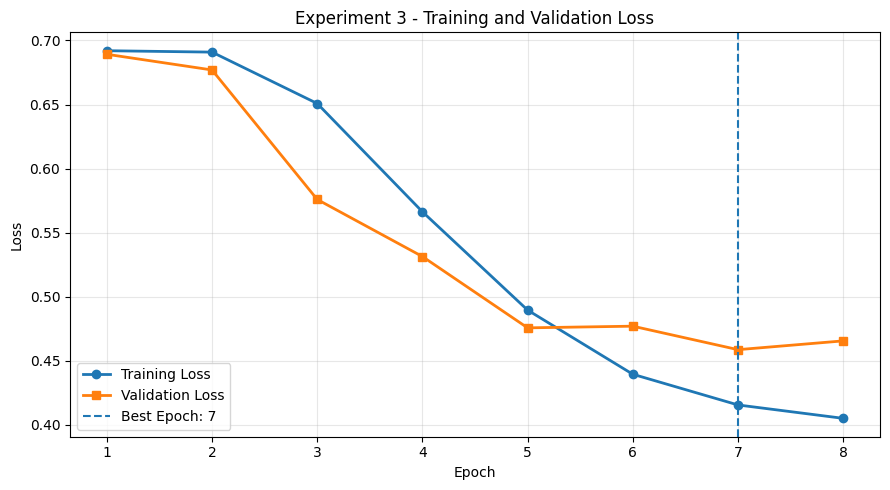

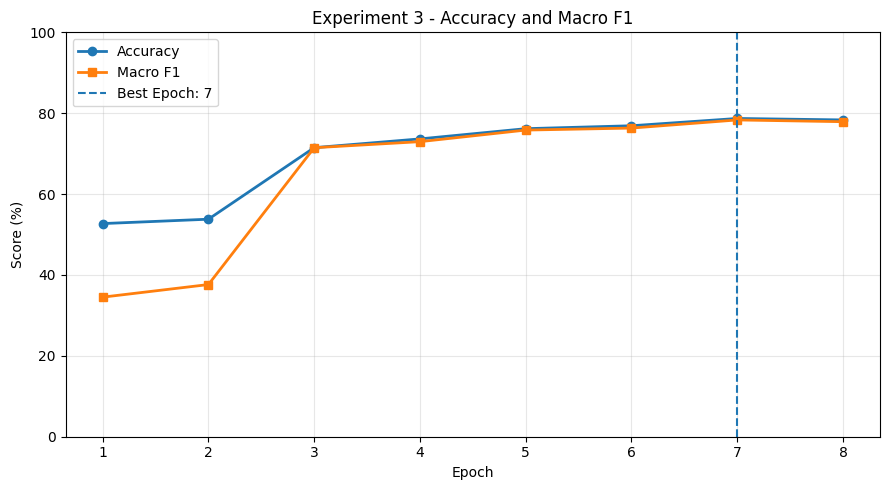

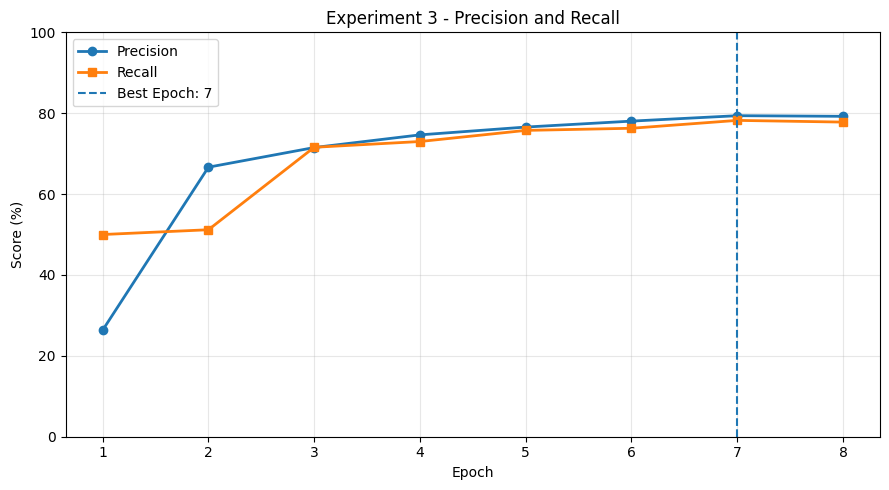

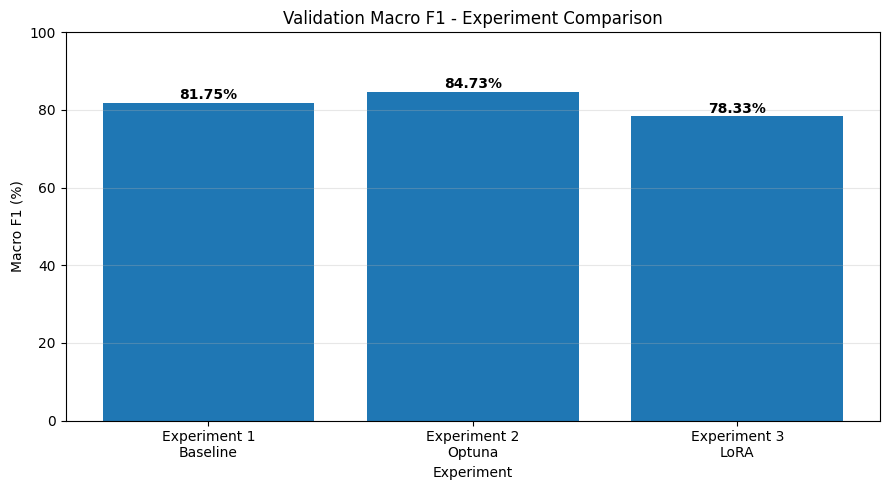


ALL EXPERIMENT 3 GRAPHS SAVED
/kaggle/working/RTE_Challenge/experiment3_lora/results/exp3_loss.png
/kaggle/working/RTE_Challenge/experiment3_lora/results/exp3_accuracy_f1.png
/kaggle/working/RTE_Challenge/experiment3_lora/results/exp3_precision_recall.png
/kaggle/working/RTE_Challenge/experiment3_lora/results/exp3_comparison.png
/kaggle/working/RTE_Challenge/experiment3_lora/results/training_history.csv

Best Epoch: 7
Best Macro F1: 78.33%


In [70]:

import os
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# LOAD EXPERIMENT 3 TRAINING HISTORY
# ==========================================

EXP3_RESULTS_DIR = (
    "/kaggle/working/RTE_Challenge/experiment3_lora/results"
)

os.makedirs(EXP3_RESULTS_DIR, exist_ok=True)

df = pd.DataFrame(history_exp3)

epochs = df["epoch"]

# Convert metrics from fractions to percentages
accuracy = df["accuracy"] * 100
precision = df["precision"] * 100
recall = df["recall"] * 100
macro_f1 = df["macro_f1"] * 100

# Best epoch
best_idx = df["macro_f1"].idxmax()
best_epoch = int(df.loc[best_idx, "epoch"])

# ==========================================
# GRAPH 1: TRAINING LOSS VS VALIDATION LOSS
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, df["train_loss"],
    marker="o", linewidth=2, label="Training Loss"
)

plt.plot(
    epochs, df["val_loss"],
    marker="s", linewidth=2, label="Validation Loss"
)

plt.axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("Experiment 3 - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EXP3_RESULTS_DIR, "exp3_loss.png"),
    dpi=300
)
plt.show()
plt.close()

# ==========================================
# GRAPH 2: ACCURACY VS MACRO F1
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, accuracy,
    marker="o", linewidth=2, label="Accuracy"
)

plt.plot(
    epochs, macro_f1,
    marker="s", linewidth=2, label="Macro F1"
)

plt.axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("Experiment 3 - Accuracy and Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.xticks(epochs)
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EXP3_RESULTS_DIR, "exp3_accuracy_f1.png"),
    dpi=300
)
plt.show()
plt.close()

# ==========================================
# GRAPH 3: PRECISION VS RECALL
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, precision,
    marker="o", linewidth=2, label="Precision"
)

plt.plot(
    epochs, recall,
    marker="s", linewidth=2, label="Recall"
)

plt.axvline(
    best_epoch, linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("Experiment 3 - Precision and Recall")
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.xticks(epochs)
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EXP3_RESULTS_DIR, "exp3_precision_recall.png"),
    dpi=300
)
plt.show()
plt.close()

# ==========================================
# GRAPH 4: EXPERIMENT COMPARISON
# ==========================================

experiments = [
    "Experiment 1\nBaseline",
    "Experiment 2\nOptuna",
    "Experiment 3\nLoRA"
]

f1_scores = [81.75, 84.73, 78.33]

plt.figure(figsize=(9, 5))

bars = plt.bar(experiments, f1_scores)

plt.title("Validation Macro F1 - Experiment Comparison")
plt.xlabel("Experiment")
plt.ylabel("Macro F1 (%)")
plt.ylim(0, 100)

for bar, score in zip(bars, f1_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(EXP3_RESULTS_DIR, "exp3_comparison.png"),
    dpi=300
)
plt.show()
plt.close()

# ==========================================
# SAVE TRAINING HISTORY CSV
# ==========================================

df.to_csv(
    os.path.join(EXP3_RESULTS_DIR, "training_history.csv"),
    index=False
)

print("\n" + "=" * 55)
print("ALL EXPERIMENT 3 GRAPHS SAVED")
print("=" * 55)

for filename in [
    "exp3_loss.png",
    "exp3_accuracy_f1.png",
    "exp3_precision_recall.png",
    "exp3_comparison.png",
    "training_history.csv"
]:
    print(os.path.join(EXP3_RESULTS_DIR, filename))

print("\nBest Epoch:", best_epoch)
print(f"Best Macro F1: {macro_f1.max():.2f}%")



In [71]:

import shutil
import os

source_dir = "/kaggle/working/RTE_Challenge/experiment3_lora"

zip_path = "/kaggle/working/Experiment3_LoRA_Complete"

# Create ZIP archive
shutil.make_archive(zip_path, "zip", source_dir)

final_zip = zip_path + ".zip"

print("=" * 55)
print("EXPERIMENT 3 SAVED SUCCESSFULLY")
print("=" * 55)
print("File:", final_zip)
print(
    "Size:",
    round(os.path.getsize(final_zip) / (1024 * 1024), 2),
    "MB"
)


EXPERIMENT 3 SAVED SUCCESSFULLY
File: /kaggle/working/Experiment3_LoRA_Complete.zip
Size: 5.76 MB


In [72]:
import shutil

shutil.make_archive(
    "/kaggle/working/Experiment1_Model",
    "zip",
    "/kaggle/working/RTE_Challenge/models/deberta_base_experiment1"
)

'/kaggle/working/Experiment1_Model.zip'

In [73]:
from IPython.display import FileLink, display

file_path = "/kaggle/working/Experiment1_Model.zip"

display(FileLink(file_path))

/kaggle/working/Experiment1_Model.zip

In [75]:
import os

file_path = "/kaggle/working/Experiment1_Model.zip"

print("Exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("Size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")

Exists: True
Size: 555.04 MB


In [ ]:

from IPython.display import HTML, display
import base64

file_path = "/kaggle/working/Experiment1_Model.zip"

with open(file_path, "rb") as f:
    encoded = base64.b64encode(f.read()).decode()

display(HTML(f'''
<a download="Experiment1_Model.zip"
   href="data:application/zip;base64,{encoded}">
   Click here to download Experiment1_Model.zip
</a>
'''))


In [77]:

import os

zip_path = "/kaggle/working/Experiment1_Model.zip"
output_prefix = "/kaggle/working/Experiment1_part_"

# Split into 95 MB chunks
!split -b 95M -d -a 2 "{zip_path}" "{output_prefix}"

print("ZIP split successfully!")

for filename in sorted(os.listdir("/kaggle/working")):
    if filename.startswith("Experiment1_part_"):
        path = os.path.join("/kaggle/working", filename)
        print(filename, round(os.path.getsize(path)/(1024**2), 2), "MB")


ZIP split successfully!
Experiment1_part_00 95.0 MB
Experiment1_part_01 95.0 MB
Experiment1_part_02 95.0 MB
Experiment1_part_03 95.0 MB
Experiment1_part_04 95.0 MB
Experiment1_part_05 80.04 MB


In [78]:

from IPython.display import FileLink, display
import os

for i in range(6):
    filename = f"/kaggle/working/Experiment1_part_{i:02d}"

    if os.path.exists(filename):
        print(f"Download part {i:02d}:")
        display(FileLink(filename))


Download part 00:


/kaggle/working/Experiment1_part_00

Download part 01:


/kaggle/working/Experiment1_part_01

Download part 02:


/kaggle/working/Experiment1_part_02

... (2 outputs left out)

Download part 04:


/kaggle/working/Experiment1_part_04

Download part 05:


/kaggle/working/Experiment1_part_05

In [79]:

!pip install -q google-api-python-client google-auth-httplib2 google-auth-oauthlib
print("Google Drive packages installed.")


Google Drive packages installed.


In [80]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Macro F1"],
    "Experiment 1 - Baseline": [81.95, 82.31, 81.62, 81.75],
    "Experiment 2 - Optuna": [84.84, 84.97, 84.64, 84.73],
    "Experiment 3 - LoRA": [78.70, 79.39, 78.23, 78.33]
})

print("=" * 75)
print("RTE CHALLENGE - MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(comparison)


RTE CHALLENGE - MODEL PERFORMANCE COMPARISON


,Metric,Experiment 1 - Baseline,Experiment 2 - Optuna,Experiment 3 - LoRA
0,Accuracy,81.95,84.84,78.70
1,Precision,82.31,84.97,79.39
2,Recall,81.62,84.64,78.23
3,Macro F1,81.75,84.73,78.33


In [81]:

parameters = pd.DataFrame({
    "Parameter": [
        "Total parameters",
        "Trainable parameters",
        "Frozen parameters",
        "Trainable percentage"
    ],
    "Experiment 1": [
        184423682, 184423682, 0, 100.0
    ],
    "Experiment 2": [
        184423682, 184423682, 0, 100.0
    ],
    "Experiment 3 - LoRA": [
        185458180, 1034498, 184423682, 0.5578
    ]
})

display(parameters)


,Parameter,Experiment 1,Experiment 2,Experiment 3 - LoRA
0,Total parameters,184423682.0,184423682.0,1.854582e+08
1,Trainable parameters,184423682.0,184423682.0,1.034498e+06
2,Frozen parameters,0.0,0.0,1.844237e+08
3,Trainable percentage,100.0,100.0,5.578000e-01


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/RTE/model_comparison.png'

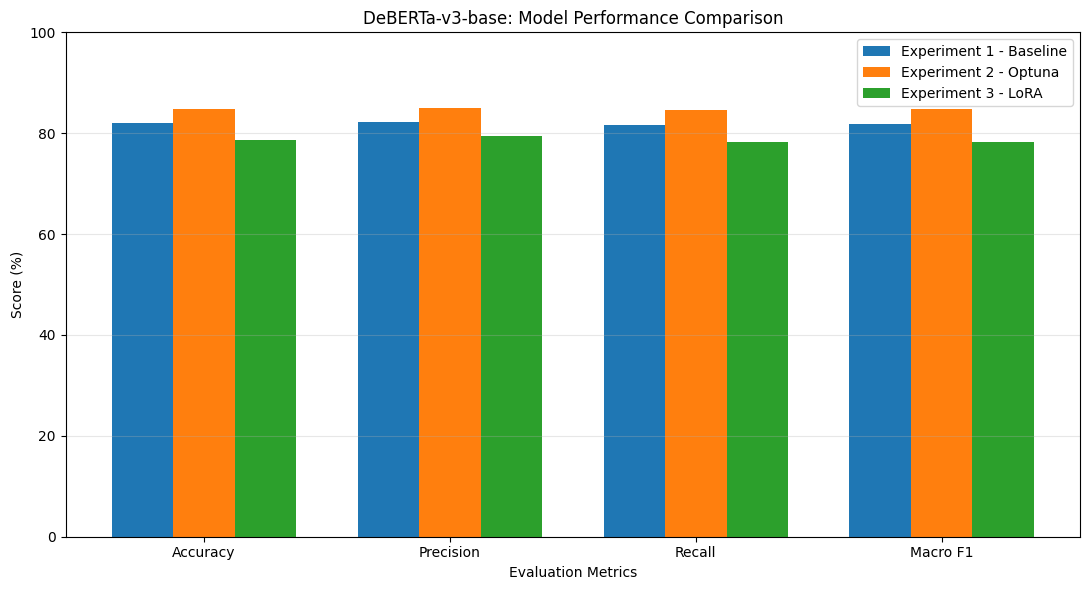

In [82]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "Macro F1"]

exp1 = [81.95, 82.31, 81.62, 81.75]
exp2 = [84.84, 84.97, 84.64, 84.73]
exp3 = [78.70, 79.39, 78.23, 78.33]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(x - width, exp1, width, label="Experiment 1 - Baseline")
plt.bar(x, exp2, width, label="Experiment 2 - Optuna")
plt.bar(x + width, exp3, width, label="Experiment 3 - LoRA")

plt.title("DeBERTa-v3-base: Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/RTE/model_comparison.png",
    dpi=300
)

plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/RTE/model_comparison.png'

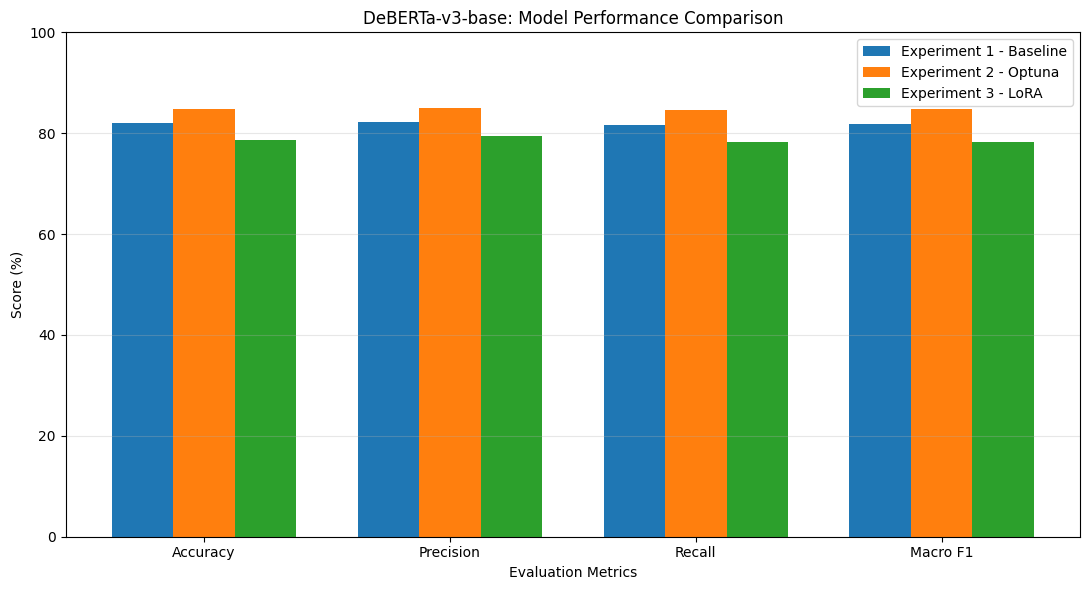

In [83]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "Macro F1"]

exp1 = [81.95, 82.31, 81.62, 81.75]
exp2 = [84.84, 84.97, 84.64, 84.73]
exp3 = [78.70, 79.39, 78.23, 78.33]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(x - width, exp1, width, label="Experiment 1 - Baseline")
plt.bar(x, exp2, width, label="Experiment 2 - Optuna")
plt.bar(x + width, exp3, width, label="Experiment 3 - LoRA")

plt.title("DeBERTa-v3-base: Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/RTE/model_comparison.png",
    dpi=300
)

plt.show()


In [84]:

ranking = {
    "Experiment 1 - Baseline": 81.75,
    "Experiment 2 - Optuna": 84.73,
    "Experiment 3 - LoRA": 78.33
}

print("\nFINAL MODEL RANKING")
print("=" * 50)

for rank, (name, score) in enumerate(
    sorted(ranking.items(), key=lambda x: x[1], reverse=True),
    start=1
):
    print(f"{rank}. {name}: {score:.2f}% Macro F1")

print("\nBest model: Experiment 2 - Optuna")



FINAL MODEL RANKING
1. Experiment 2 - Optuna: 84.73% Macro F1
2. Experiment 1 - Baseline: 81.75% Macro F1
3. Experiment 3 - LoRA: 78.33% Macro F1

Best model: Experiment 2 - Optuna


In [85]:

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# PROJECT DIRECTORY
# ==========================================

PROJECT_DIR = "/content/drive/MyDrive/RTE"
RESULTS_DIR = os.path.join(PROJECT_DIR, "final_comparison")

os.makedirs(RESULTS_DIR, exist_ok=True)

# ==========================================
# EXPERIMENT RESULTS
# ==========================================

experiments = {
    "Experiment 1 - Baseline": {
        "accuracy": 81.95,
        "precision": 82.31,
        "recall": 81.62,
        "macro_f1": 81.75,
        "best_epoch": 2,
        "method": "Full Fine-tuning"
    },

    "Experiment 2 - Optuna": {
        "accuracy": 84.84,
        "precision": 84.97,
        "recall": 84.64,
        "macro_f1": 84.73,
        "best_epoch": 4,
        "method": "Full Fine-tuning + Optuna"
    },

    "Experiment 3 - LoRA": {
        "accuracy": 78.70,
        "precision": 79.39,
        "recall": 78.23,
        "macro_f1": 78.33,
        "best_epoch": 7,
        "method": "LoRA Fine-tuning"
    }
}

# ==========================================
# PARAMETER INFORMATION
# ==========================================

BASE_PARAMS = 184_423_682
LORA_PARAMS = 1_034_498

parameter_info = {
    "Experiment 1 - Baseline": {
        "base_parameters": BASE_PARAMS,
        "additional_parameters": 0,
        "total_parameters": BASE_PARAMS,
        "trainable_parameters": BASE_PARAMS,
        "frozen_parameters": 0
    },

    "Experiment 2 - Optuna": {
        "base_parameters": BASE_PARAMS,
        "additional_parameters": 0,
        "total_parameters": BASE_PARAMS,
        "trainable_parameters": BASE_PARAMS,
        "frozen_parameters": 0
    },

    "Experiment 3 - LoRA": {
        "base_parameters": BASE_PARAMS,
        "additional_parameters": LORA_PARAMS,
        "total_parameters": BASE_PARAMS + LORA_PARAMS,
        "trainable_parameters": LORA_PARAMS,
        "frozen_parameters": BASE_PARAMS
    }
}

print("Experiment results and parameter information loaded.")
print("Output directory:", RESULTS_DIR)


Experiment results and parameter information loaded.
Output directory: /content/drive/MyDrive/RTE/final_comparison


In [86]:

performance_df = pd.DataFrame(experiments).T

performance_df.index.name = "Model"

print("=" * 85)
print("RTE CHALLENGE - PERFORMANCE COMPARISON")
print("=" * 85)

display(performance_df.round(2))

performance_df.to_csv(
    os.path.join(RESULTS_DIR, "performance_comparison.csv")
)

print("Performance comparison CSV saved.")


RTE CHALLENGE - PERFORMANCE COMPARISON


,accuracy,precision,recall,macro_f1,best_epoch,method
Model,,,,,,
Experiment 1 - Baseline,81.95,82.31,81.62,81.75,2,Full Fine-tuning
Experiment 2 - Optuna,84.84,84.97,84.64,84.73,4,Full Fine-tuning + Optuna
Experiment 3 - LoRA,78.7,79.39,78.23,78.33,7,LoRA Fine-tuning


Performance comparison CSV saved.


In [87]:

parameter_df = pd.DataFrame(parameter_info).T

parameter_df["trainable_percentage"] = (
    parameter_df["trainable_parameters"] /
    parameter_df["total_parameters"]
) * 100

parameter_df["frozen_percentage"] = (
    parameter_df["frozen_parameters"] /
    parameter_df["total_parameters"]
) * 100

parameter_df.index.name = "Model"

print("=" * 85)
print("MODEL PARAMETER COMPARISON")
print("=" * 85)

display(parameter_df.round(4))

parameter_df.to_csv(
    os.path.join(RESULTS_DIR, "parameter_comparison.csv")
)

print("Parameter comparison CSV saved.")


MODEL PARAMETER COMPARISON


,base_parameters,additional_parameters,total_parameters,trainable_parameters,frozen_parameters,trainable_percentage,frozen_percentage
Model,,,,,,,
Experiment 1 - Baseline,184423682,0,184423682,184423682,0,100.0000,0.0000
Experiment 2 - Optuna,184423682,0,184423682,184423682,0,100.0000,0.0000
Experiment 3 - LoRA,184423682,1034498,185458180,1034498,184423682,0.5578,99.4422


Parameter comparison CSV saved.


In [88]:

hyperparameters = {
    "Experiment 1 - Baseline": {
        "Architecture": "DeBERTa-v3-base",
        "Learning Rate": 1e-5,
        "Weight Decay": 0.01,
        "Batch Size": 16,
        "Maximum Epochs": 5,
        "Warmup Ratio": 0.06,
        "Maximum Sequence Length": 256,
        "Optimization": "AdamW",
        "Fine-tuning": "Full"
    },

    "Experiment 2 - Optuna": {
        "Architecture": "DeBERTa-v3-base",
        "Learning Rate": 1.7781056670396774e-5,
        "Weight Decay": 0.0020584494295802446,
        "Batch Size": 16,
        "Maximum Epochs": 8,
        "Warmup Ratio": 0.11729188669457949,
        "Maximum Sequence Length": 256,
        "Optimization": "AdamW + Optuna",
        "Fine-tuning": "Full"
    },

    "Experiment 3 - LoRA": {
        "Architecture": "DeBERTa-v3-base",
        "Learning Rate": 5e-5,
        "Weight Decay": 0.01,
        "Batch Size": 16,
        "Maximum Epochs": 8,
        "Warmup Ratio": 0.06,
        "Maximum Sequence Length": 256,
        "Optimization": "AdamW",
        "Fine-tuning": "LoRA (r=8, alpha=16)"
    }
}

hyperparameter_df = pd.DataFrame(hyperparameters).T

display(hyperparameter_df)

hyperparameter_df.to_csv(
    os.path.join(RESULTS_DIR, "hyperparameter_comparison.csv")
)

print("Hyperparameter comparison saved.")


,Architecture,Learning Rate,Weight Decay,Batch Size,Maximum Epochs,Warmup Ratio,Maximum Sequence Length,Optimization,Fine-tuning
Experiment 1 - Baseline,DeBERTa-v3-base,0.00001,0.01,16,5,0.06,256,AdamW,Full
Experiment 2 - Optuna,DeBERTa-v3-base,0.000018,0.002058,16,8,0.117292,256,AdamW + Optuna,Full
Experiment 3 - LoRA,DeBERTa-v3-base,0.00005,0.01,16,8,0.06,256,AdamW,"LoRA (r=8, alpha=16)"


Hyperparameter comparison saved.


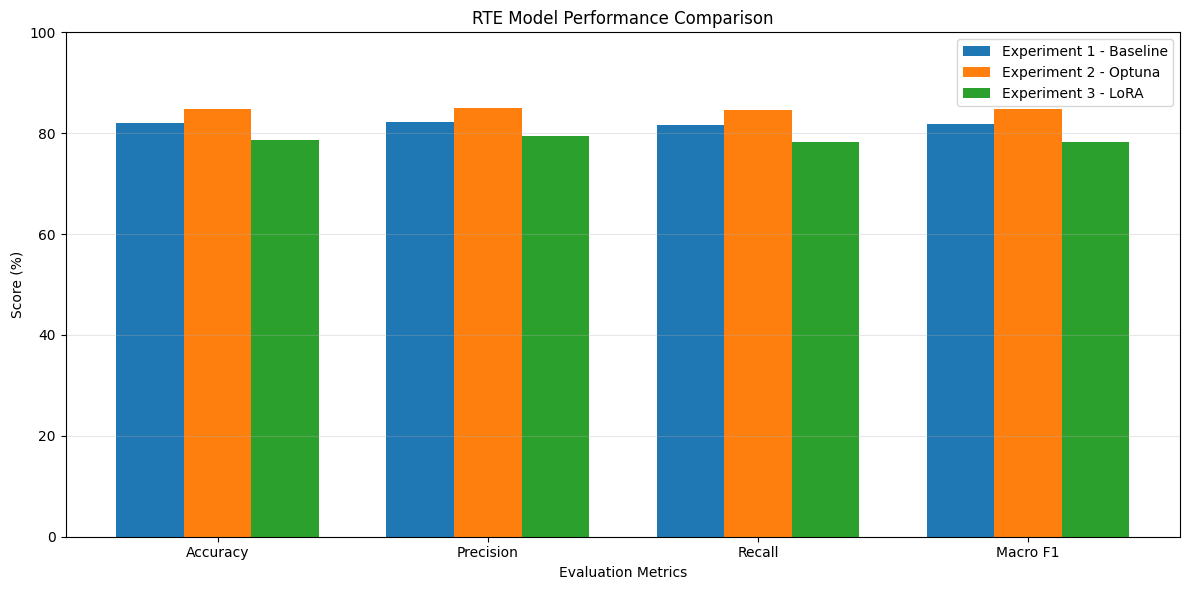

In [89]:

metrics = ["accuracy", "precision", "recall", "macro_f1"]

metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1"
]

model_names = list(experiments.keys())

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))

for i, model in enumerate(model_names):
    values = [
        experiments[model][metric]
        for metric in metrics
    ]

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=model
    )

plt.title("RTE Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.xticks(x, metric_labels)
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "all_metrics_comparison.png"),
    dpi=300
)

plt.show()


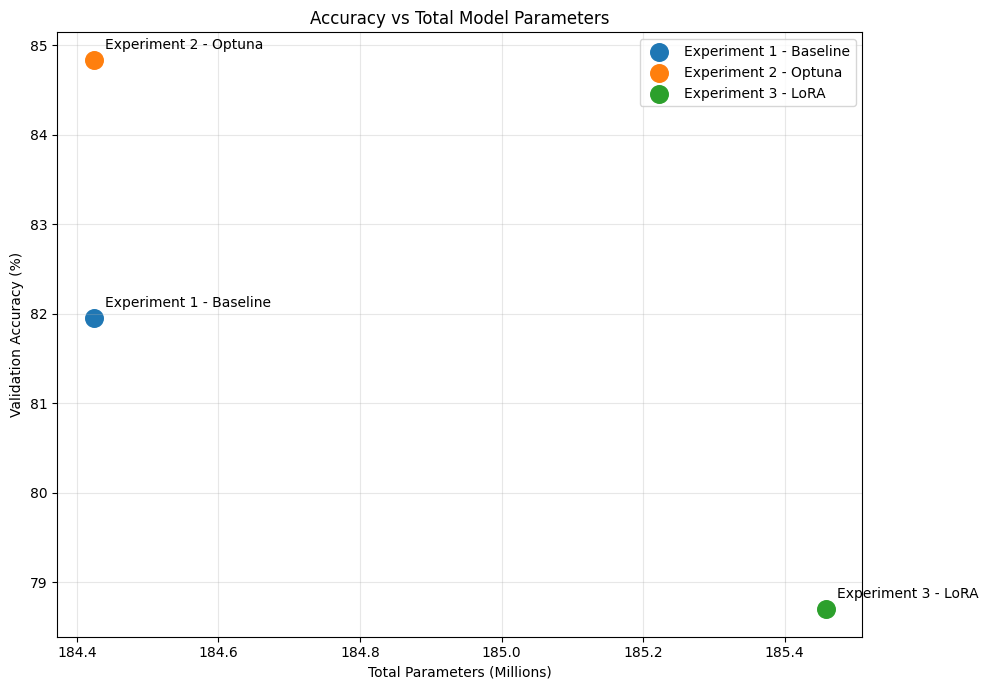

In [90]:

plt.figure(figsize=(10, 7))

for model in model_names:
    params = parameter_info[model]["total_parameters"] / 1e6
    accuracy = experiments[model]["accuracy"]

    plt.scatter(
        params,
        accuracy,
        s=160,
        label=model
    )

    plt.annotate(
        model,
        (params, accuracy),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title("Accuracy vs Total Model Parameters")
plt.xlabel("Total Parameters (Millions)")
plt.ylabel("Validation Accuracy (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "accuracy_vs_parameters.png"),
    dpi=300
)

plt.show()


In [91]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Replace these with predictions generated by your actual models.
# Each array must contain 277 predictions in the same order as val_dataset.

# predictions_by_model = {
#     "Experiment 1 - Baseline": exp1_predictions,
#     "Experiment 2 - Optuna": exp2_predictions,
#     "Experiment 3 - LoRA": exp3_predictions
# }

if "predictions_by_model" in globals() and "y_true" in globals():

    for model_name, predictions in predictions_by_model.items():

        cm = confusion_matrix(
            y_true,
            predictions,
            labels=[0, 1]
        )

        display_obj = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Not Entailment", "Entailment"]
        )

        fig, ax = plt.subplots(figsize=(6, 5))
        display_obj.plot(
            ax=ax,
            cmap="Blues",
            values_format="d"
        )

        ax.set_title(model_name)
        plt.tight_layout()

        safe_name = model_name.lower().replace(" ", "_")

        plt.savefig(
            os.path.join(
                RESULTS_DIR,
                f"{safe_name}_confusion_matrix.png"
            ),
            dpi=300
        )

        plt.show()
        plt.close()

else:
    print("Run model inference first to generate predictions.")


Run model inference first to generate predictions.


In [92]:

# Required variables:
#
# y_true = actual validation labels
#
# predictions_by_model = {
#     "Experiment 1 - Baseline": exp1_predictions,
#     "Experiment 2 - Optuna": exp2_predictions,
#     "Experiment 3 - LoRA": exp3_predictions
# }

if "predictions_by_model" in globals() and "y_true" in globals():

    predictions_df = pd.DataFrame({
        "actual_label": [
            "entailment" if x == 1 else "not_entailment"
            for x in y_true
        ]
    })

    for model_name, predictions in predictions_by_model.items():

        column_name = model_name.lower().replace(" ", "_")

        predictions_df[column_name] = [
            "entailment" if x == 1 else "not_entailment"
            for x in predictions
        ]

    predictions_path = os.path.join(
        RESULTS_DIR,
        "development_set_predictions.csv"
    )

    predictions_df.to_csv(
        predictions_path,
        index=False
    )

    display(predictions_df.head(10))

    print("Predictions saved:", predictions_path)

else:
    print("Generate predictions from all three models first.")


Generate predictions from all three models first.


In [93]:

import os

PROJECT_DIR = "/content/drive/MyDrive/RTE"

# Check model checkpoints
paths = {
    "Experiment 1": os.path.join(
        PROJECT_DIR, "experiment1_baseline",
        "model_extracted"
    ),
    "Experiment 2": os.path.join(
        PROJECT_DIR, "experiment2_optuna",
        "extracted", "best_model"
    ),
    "Experiment 3": os.path.join(
        PROJECT_DIR, "experiment3_lora",
        "extracted", "best_model"
    )
}

print("=" * 65)
print("MODEL CHECKPOINT VERIFICATION")
print("=" * 65)

for name, path in paths.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        for file in os.listdir(path):
            print("  ", file)

# Find development dataset
print("\n" + "=" * 65)
print("SEARCHING FOR DEVELOPMENT DATASET")
print("=" * 65)

for root, dirs, files in os.walk(PROJECT_DIR):
    for file in files:
        if file.lower() in [
            "val.jsonl", "dev.jsonl",
            "validation.jsonl", "val.json",
            "dev.json"
        ]:
            print(os.path.join(root, file))


MODEL CHECKPOINT VERIFICATION

Experiment 1
Path: /content/drive/MyDrive/RTE/experiment1_baseline/model_extracted
Exists: False

Experiment 2
Path: /content/drive/MyDrive/RTE/experiment2_optuna/extracted/best_model
Exists: False

Experiment 3
Path: /content/drive/MyDrive/RTE/experiment3_lora/extracted/best_model
Exists: False

SEARCHING FOR DEVELOPMENT DATASET


In [94]:

import os

BASE_DIR = "/kaggle/working/RTE_Challenge"

print("=" * 70)
print("KAGGLE RTE PROJECT INSPECTION")
print("=" * 70)

for root, dirs, files in os.walk(BASE_DIR):

    level = root.replace(BASE_DIR, "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"\n{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")


KAGGLE RTE PROJECT INSPECTION

RTE_Challenge/

    results/
        experiment1_history.csv
        experiment1_summary.json
        experiment1_accuracy_f1.png
        experiment1_precision_recall.png
        experiment1_confusion_matrix.png
        experiment1_loss.png

    experiment2_optuna/

        results/
            exp2_confusion_matrix.png
            exp2_loss.png
            exp2_precision_recall.png
            experiment2_history.csv
            experiment2_training_history.csv
            experiment2_best_metrics.json
            exp2_accuracy_f1.png

        logs/

        best_model/
            model.safetensors
            tokenizer.json
            tokenizer_config.json
            config.json

    optuna_experiment/

    logs/

    experiment3_lora/

        results/
            exp3_comparison.png
            exp3_precision_recall.png
            best_metrics.json
            exp3_accuracy_f1.png
            exp3_loss.png
            training_history.csv

       

In [95]:

import os

print("=" * 65)
print("SEARCHING KAGGLE INPUT DATASETS")
print("=" * 65)

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() in [
            "val.jsonl",
            "dev.jsonl",
            "validation.jsonl",
            "val.json",
            "dev.json"
        ]:
            print("FOUND:", os.path.join(root, file))


SEARCHING KAGGLE INPUT DATASETS
FOUND: /kaggle/input/datasets/rohitsah402/rte-challenge/val.jsonl


In [96]:

import os
import json
import torch
import pandas as pd
import transformers
import peft

BASE_DIR = "/kaggle/working/RTE_Challenge"

EXP1_PATH = os.path.join(
    BASE_DIR, "models", "deberta_base_experiment1"
)

EXP2_PATH = os.path.join(
    BASE_DIR, "experiment2_optuna", "best_model"
)

EXP3_PATH = os.path.join(
    BASE_DIR, "experiment3_lora", "best_model"
)

VAL_PATH = "/kaggle/input/datasets/rohitsah402/rte-challenge/val.jsonl"

print("=" * 65)
print("ENVIRONMENT")
print("=" * 65)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

print("\n" + "=" * 65)
print("CHECKPOINTS")
print("=" * 65)

for name, path in [
    ("Experiment 1", EXP1_PATH),
    ("Experiment 2", EXP2_PATH),
    ("Experiment 3", EXP3_PATH)
]:
    print(name, ":", os.path.exists(path))
    print("Files:", os.listdir(path) if os.path.exists(path) else "Missing")

print("\n" + "=" * 65)
print("VALIDATION DATASET")
print("=" * 65)

val_df = pd.read_json(VAL_PATH, lines=True)

print("Number of examples:", len(val_df))
print("Columns:", val_df.columns.tolist())
print("\nLabel distribution:")
print(val_df["label"].value_counts())

print("\nSample records:")
display(val_df.head(3))

print("\nMissing values:")
print(val_df[["premise", "hypothesis", "label"]].isnull().sum())

assert len(val_df) == 277, "Unexpected validation dataset size!"
assert val_df[["premise", "hypothesis", "label"]].isnull().sum().sum() == 0


ENVIRONMENT
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
PEFT: 0.21.2
GPU: Tesla T4

CHECKPOINTS
Experiment 1 : True
Files: ['model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'config.json']
Experiment 2 : True
Files: ['model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'config.json']
Experiment 3 : True
Files: ['adapter_config.json', 'tokenizer.json', 'tokenizer_config.json', 'adapter_model.safetensors', 'README.md']

VALIDATION DATASET
Number of examples: 277
Columns: ['premise', 'hypothesis', 'label', 'idx']

Label distribution:
label
entailment        146
not_entailment    131
Name: count, dtype: int64

Sample records:


,premise,hypothesis,label,idx
0,"Dana Reeve, the widow of the actor Christopher...",Christopher Reeve had an accident.,not_entailment,0
1,"Yet, we now are discovering that antibiotics a...",Bacteria is winning the war against antibiotics.,entailment,1
2,Cairo is now home to some 15 million people - ...,15 million tonnes of rubbish are produced dail...,not_entailment,2



Missing values:
premise       0
hypothesis    0
label         0
dtype: int64


COMPARISONS


In [97]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

BASE_DIR = "/kaggle/working/RTE_Challenge"
OUTPUT_DIR = os.path.join(BASE_DIR, "final_comparison")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify inference results exist
assert "predictions_by_model" in globals(), (
    "Run the inference cell first."
)
assert "y_true" in globals(), (
    "Ground-truth labels are missing. Run inference first."
)

MODEL_NAMES = [
    "Experiment 1",
    "Experiment 2",
    "Experiment 3"
]

for name in MODEL_NAMES:
    assert name in predictions_by_model, f"{name} predictions missing"

    assert len(predictions_by_model[name]) == len(y_true), (
        f"Prediction length mismatch: {name}"
    )

print("All three prediction arrays verified.")
print("Validation examples:", len(y_true))
print("Output directory:", OUTPUT_DIR)


AssertionError: Run the inference cell first.

In [98]:

import os
import gc
import json
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import PeftConfig, PeftModel

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ==========================================
# PATHS
# ==========================================

BASE_DIR = "/kaggle/working/RTE_Challenge"

EXP1_PATH = f"{BASE_DIR}/models/deberta_base_experiment1"
EXP2_PATH = f"{BASE_DIR}/experiment2_optuna/best_model"
EXP3_PATH = f"{BASE_DIR}/experiment3_lora/best_model"

VAL_PATH = "/kaggle/input/datasets/rohitsah402/rte-challenge/val.jsonl"

OUTPUT_DIR = f"{BASE_DIR}/inference_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 16
MAX_LENGTH = 256

LABEL2ID = {
    "not_entailment": 0,
    "entailment": 1
}

# ==========================================
# LOAD VALIDATION DATA
# ==========================================

val_df = pd.read_json(VAL_PATH, lines=True)

y_true = val_df["label"].map(LABEL2ID).to_numpy()

assert not pd.isna(y_true).any()

premises = val_df["premise"].astype(str).tolist()
hypotheses = val_df["hypothesis"].astype(str).tolist()

print("Validation samples:", len(val_df))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

# ==========================================
# INFERENCE FUNCTION
# ==========================================

def generate_predictions(model, tokenizer, name):

    model.to(DEVICE)
    model.eval()

    predictions = []

    for start in range(0, len(premises), BATCH_SIZE):

        end = min(start + BATCH_SIZE, len(premises))

        inputs = tokenizer(
            premises[start:end],
            hypotheses[start:end],
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
        }

        with torch.inference_mode():

            if DEVICE.type == "cuda":
                with torch.autocast("cuda", dtype=torch.float16):
                    logits = model(**inputs).logits
            else:
                logits = model(**inputs).logits

            batch_predictions = logits.argmax(dim=-1)

        predictions.extend(batch_predictions.cpu().tolist())

        print(
            f"\r{name}: {end}/{len(val_df)}",
            end=""
        )

    print()

    return np.array(predictions)


# ==========================================
# EXPERIMENT 1
# ==========================================

print("\nLoading Experiment 1...")

tokenizer1 = AutoTokenizer.from_pretrained(EXP1_PATH)

model1 = AutoModelForSequenceClassification.from_pretrained(
    EXP1_PATH
)

pred_exp1 = generate_predictions(
    model1, tokenizer1, "Experiment 1"
)

del model1, tokenizer1
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None


# ==========================================
# EXPERIMENT 2
# ==========================================

print("\nLoading Experiment 2...")

tokenizer2 = AutoTokenizer.from_pretrained(EXP2_PATH)

model2 = AutoModelForSequenceClassification.from_pretrained(
    EXP2_PATH
)

pred_exp2 = generate_predictions(
    model2, tokenizer2, "Experiment 2"
)

del model2, tokenizer2
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None


# ==========================================
# EXPERIMENT 3 - LoRA
# ==========================================

print("\nLoading Experiment 3...")

tokenizer3 = AutoTokenizer.from_pretrained(EXP3_PATH)

peft_config = PeftConfig.from_pretrained(EXP3_PATH)

base_model = AutoModelForSequenceClassification.from_pretrained(
    peft_config.base_model_name_or_path,
    num_labels=2
)

model3 = PeftModel.from_pretrained(
    base_model,
    EXP3_PATH
)

pred_exp3 = generate_predictions(
    model3, tokenizer3, "Experiment 3"
)

del model3, base_model, tokenizer3
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None


# ==========================================
# STORE PREDICTIONS
# ==========================================

predictions_by_model = {
    "Experiment 1": pred_exp1,
    "Experiment 2": pred_exp2,
    "Experiment 3": pred_exp3
}

# ==========================================
# CALCULATE METRICS
# ==========================================

metrics = {}

for name, predictions in predictions_by_model.items():

    metrics[name] = {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        )),
        "recall": float(recall_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        )),
        "macro_f1": float(f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ))
    }

    print("\n", name)
    print("Accuracy :", round(metrics[name]["accuracy"] * 100, 2))
    print("Precision:", round(metrics[name]["precision"] * 100, 2))
    print("Recall   :", round(metrics[name]["recall"] * 100, 2))
    print("Macro F1 :", round(metrics[name]["macro_f1"] * 100, 2))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))


# ==========================================
# SAVE OUTPUTS
# ==========================================

prediction_df = val_df.copy()

prediction_df["true_label_id"] = y_true
prediction_df["exp1_prediction"] = pred_exp1
prediction_df["exp2_prediction"] = pred_exp2
prediction_df["exp3_prediction"] = pred_exp3

prediction_df.to_csv(
    f"{OUTPUT_DIR}/dev_predictions_all_models.csv",
    index=False
)

with open(f"{OUTPUT_DIR}/inference_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("\n==========================================")
print("INFERENCE COMPLETED")
print("==========================================")
print("Saved predictions:", OUTPUT_DIR)


Validation samples: 277
GPU: Tesla T4

Loading Experiment 1...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Experiment 1: 277/277

Loading Experiment 2...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Experiment 2: 277/277

Loading Experiment 3...


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Experiment 3: 277/277

 Experiment 1
Accuracy : 81.95
Precision: 82.31
Recall   : 81.62
Macro F1 : 81.75
Confusion matrix:
[[ 99  32]
 [ 18 128]]

 Experiment 2
Accuracy : 84.84
Precision: 84.97
Recall   : 84.64
Macro F1 : 84.73
Confusion matrix:
[[106  25]
 [ 17 129]]

 Experiment 3
Accuracy : 78.7
Precision: 79.39
Recall   : 78.23
Macro F1 : 78.33
Confusion matrix:
[[ 91  40]
 [ 19 127]]

INFERENCE COMPLETED
Saved predictions: /kaggle/working/RTE_Challenge/inference_results


In [99]:

print("Available prediction models:")

for name, predictions in predictions_by_model.items():
    print(
        name,
        "| Samples:", len(predictions),
        "| Unique predictions:", np.unique(predictions)
    )

print("\nGround truth samples:", len(y_true))


Available prediction models:
Experiment 1 | Samples: 277 | Unique predictions: [0 1]
Experiment 2 | Samples: 277 | Unique predictions: [0 1]
Experiment 3 | Samples: 277 | Unique predictions: [0 1]

Ground truth samples: 277


In [100]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

BASE_DIR = "/kaggle/working/RTE_Challenge"
OUTPUT_DIR = os.path.join(BASE_DIR, "final_comparison")
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_NAMES = [
    "Experiment 1",
    "Experiment 2",
    "Experiment 3"
]

assert all(name in predictions_by_model for name in MODEL_NAMES)
assert len(y_true) == 277

# Calculate actual metrics again
performance = []

for name in MODEL_NAMES:
    pred = np.asarray(predictions_by_model[name])

    performance.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_true, pred) * 100,
        "Precision (%)": precision_score(
            y_true, pred, average="macro", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_true, pred, average="macro", zero_division=0
        ) * 100,
        "Macro F1 (%)": f1_score(
            y_true, pred, average="macro", zero_division=0
        ) * 100,
        "Correct": int((pred == y_true).sum()),
        "Incorrect": int((pred != y_true).sum())
    })

performance_df = pd.DataFrame(performance).round(2)

display(performance_df)

performance_df.to_csv(
    f"{OUTPUT_DIR}/performance_comparison.csv",
    index=False
)

print("Saved performance_comparison.csv")


,Model,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Correct,Incorrect
0,Experiment 1,81.95,82.31,81.62,81.75,227,50
1,Experiment 2,84.84,84.97,84.64,84.73,235,42
2,Experiment 3,78.70,79.39,78.23,78.33,218,59


Saved performance_comparison.csv


In [101]:

parameter_df = pd.DataFrame([
    {
        "Model": "Experiment 1",
        "Architecture": "DeBERTa-v3-base",
        "Total Parameters": 184423682,
        "Trainable Parameters": 184423682,
        "Frozen Parameters": 0
    },
    {
        "Model": "Experiment 2",
        "Architecture": "DeBERTa-v3-base",
        "Total Parameters": 184423682,
        "Trainable Parameters": 184423682,
        "Frozen Parameters": 0
    },
    {
        "Model": "Experiment 3",
        "Architecture": "DeBERTa-v3-base + LoRA",
        "Total Parameters": 185458180,
        "Trainable Parameters": 1034498,
        "Frozen Parameters": 184423682
    }
])

parameter_df["Trainable (%)"] = (
    parameter_df["Trainable Parameters"] /
    parameter_df["Total Parameters"] * 100
)

parameter_df["Total (M)"] = (
    parameter_df["Total Parameters"] / 1e6
)

parameter_df["Trainable (M)"] = (
    parameter_df["Trainable Parameters"] / 1e6
)

display(parameter_df.round(4))

parameter_df.to_csv(
    f"{OUTPUT_DIR}/parameter_comparison.csv",
    index=False
)


,Model,Architecture,Total Parameters,Trainable Parameters,Frozen Parameters,Trainable (%),Total (M),Trainable (M)
0,Experiment 1,DeBERTa-v3-base,184423682,184423682,0,100.0000,184.4237,184.4237
1,Experiment 2,DeBERTa-v3-base,184423682,184423682,0,100.0000,184.4237,184.4237
2,Experiment 3,DeBERTa-v3-base + LoRA,185458180,1034498,184423682,0.5578,185.4582,1.0345


In [102]:

hyperparameter_df = pd.DataFrame([
    {
        "Model": "Experiment 1",
        "Method": "Full Fine-tuning",
        "Learning Rate": 1e-5,
        "Weight Decay": 0.01,
        "Batch Size": 16,
        "Max Epochs": 5,
        "Warmup Ratio": 0.06,
        "Max Length": 256,
        "Optuna Trials": 0,
        "LoRA Rank": "-"
    },
    {
        "Model": "Experiment 2",
        "Method": "Optuna + Full Fine-tuning",
        "Learning Rate": 1.7781056670396774e-5,
        "Weight Decay": 0.0020584494295802446,
        "Batch Size": 16,
        "Max Epochs": 8,
        "Warmup Ratio": 0.11729188669457949,
        "Max Length": 256,
        "Optuna Trials": 10,
        "LoRA Rank": "-"
    },
    {
        "Model": "Experiment 3",
        "Method": "LoRA Fine-tuning",
        "Learning Rate": 5e-5,
        "Weight Decay": 0.01,
        "Batch Size": 16,
        "Max Epochs": 8,
        "Warmup Ratio": 0.06,
        "Max Length": 256,
        "Optuna Trials": 0,
        "LoRA Rank": 8
    }
])

display(hyperparameter_df)

hyperparameter_df.to_csv(
    f"{OUTPUT_DIR}/hyperparameter_comparison.csv",
    index=False
)


,Model,Method,Learning Rate,Weight Decay,Batch Size,Max Epochs,Warmup Ratio,Max Length,Optuna Trials,LoRA Rank
0,Experiment 1,Full Fine-tuning,0.000010,0.010000,16,5,0.060000,256,0,-
1,Experiment 2,Optuna + Full Fine-tuning,0.000018,0.002058,16,8,0.117292,256,10,-
2,Experiment 3,LoRA Fine-tuning,0.000050,0.010000,16,8,0.060000,256,0,8


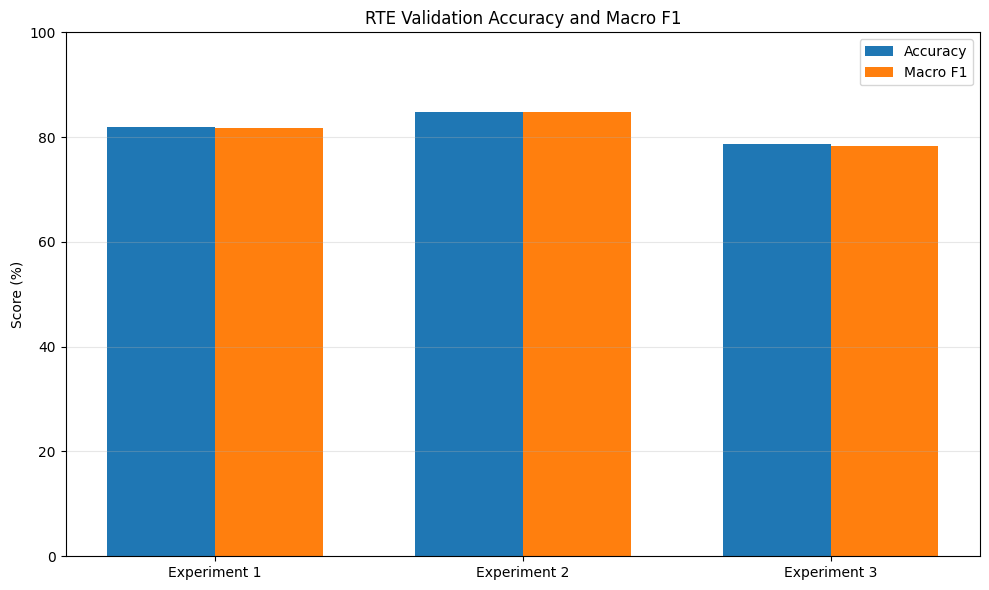

In [103]:

x = np.arange(len(performance_df))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    performance_df["Accuracy (%)"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    performance_df["Macro F1 (%)"],
    width,
    label="Macro F1"
)

plt.xticks(x, performance_df["Model"])
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title("RTE Validation Accuracy and Macro F1")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/accuracy_f1_comparison.png",
    dpi=300
)

plt.show()


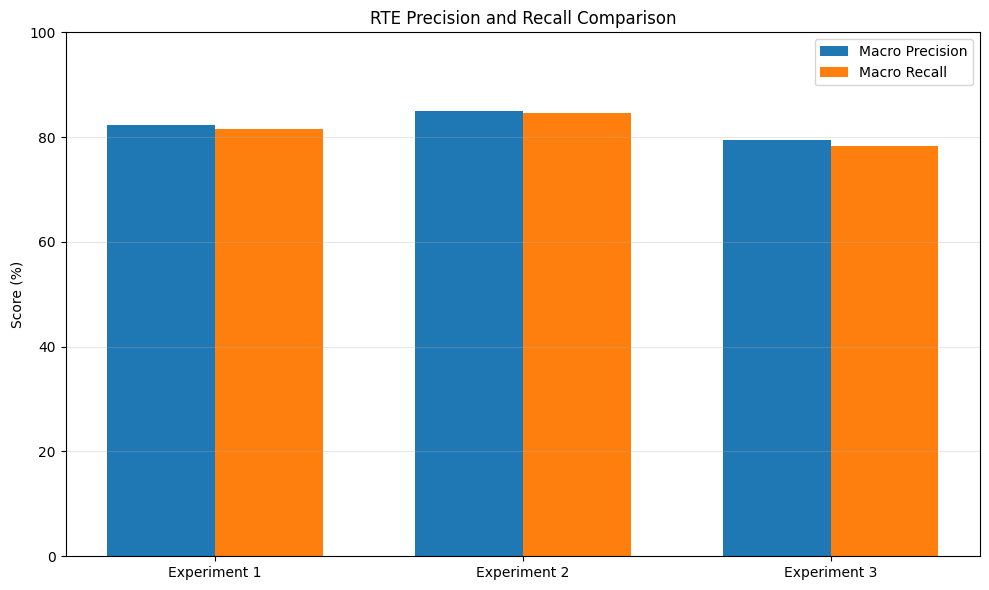

In [104]:

x = np.arange(len(performance_df))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    performance_df["Precision (%)"],
    width,
    label="Macro Precision"
)

plt.bar(
    x + width/2,
    performance_df["Recall (%)"],
    width,
    label="Macro Recall"
)

plt.xticks(x, performance_df["Model"])
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title("RTE Precision and Recall Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/precision_recall_comparison.png",
    dpi=300
)

plt.show()


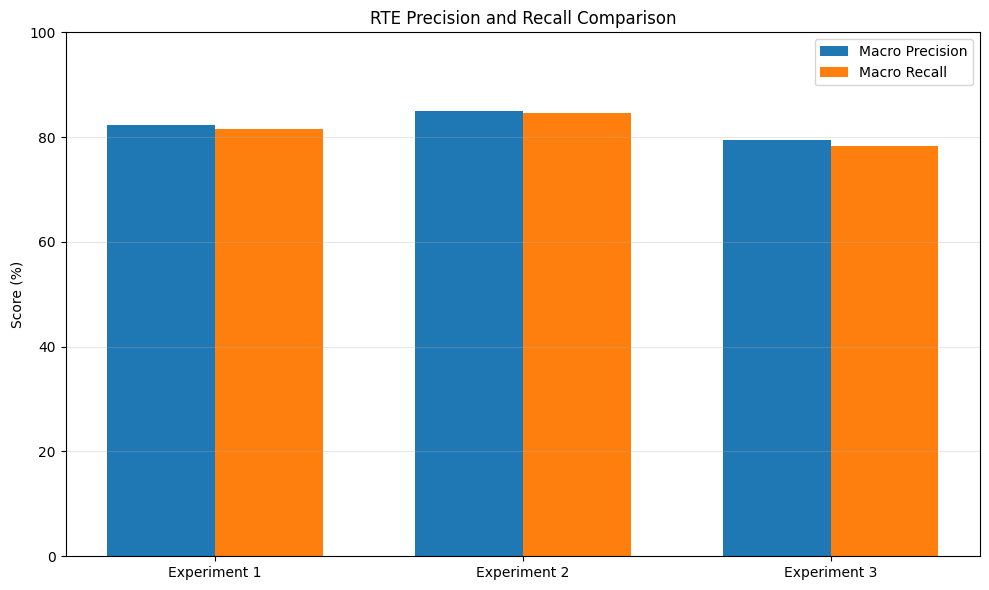

In [105]:

x = np.arange(len(performance_df))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    performance_df["Precision (%)"],
    width,
    label="Macro Precision"
)

plt.bar(
    x + width/2,
    performance_df["Recall (%)"],
    width,
    label="Macro Recall"
)

plt.xticks(x, performance_df["Model"])
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title("RTE Precision and Recall Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/precision_recall_comparison.png",
    dpi=300
)

plt.show()


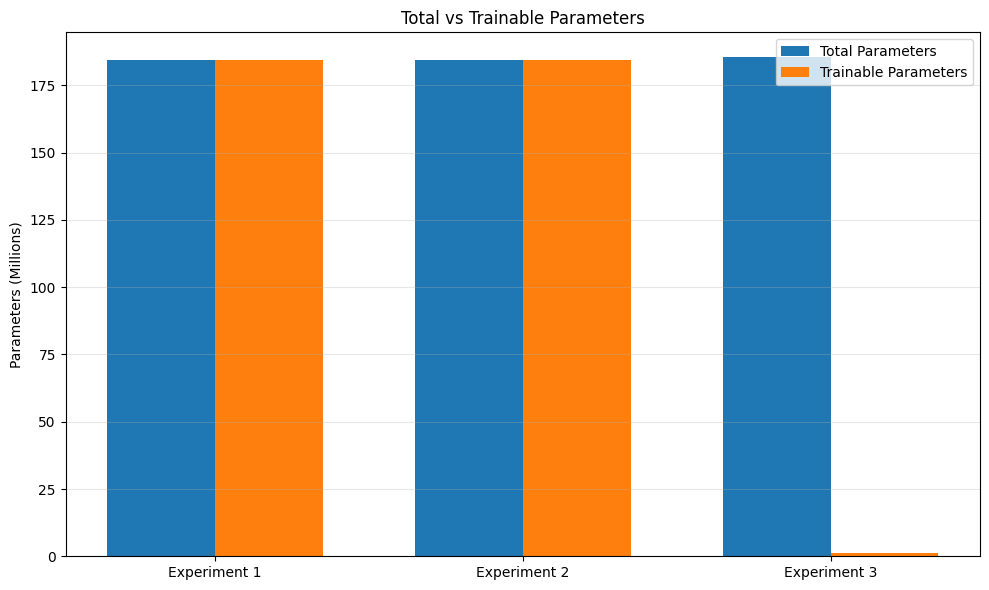

In [106]:

x = np.arange(len(parameter_df))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    parameter_df["Total (M)"],
    width,
    label="Total Parameters"
)

plt.bar(
    x + width/2,
    parameter_df["Trainable (M)"],
    width,
    label="Trainable Parameters"
)

plt.xticks(x, parameter_df["Model"])
plt.ylabel("Parameters (Millions)")
plt.title("Total vs Trainable Parameters")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/parameter_comparison.png",
    dpi=300
)

plt.show()


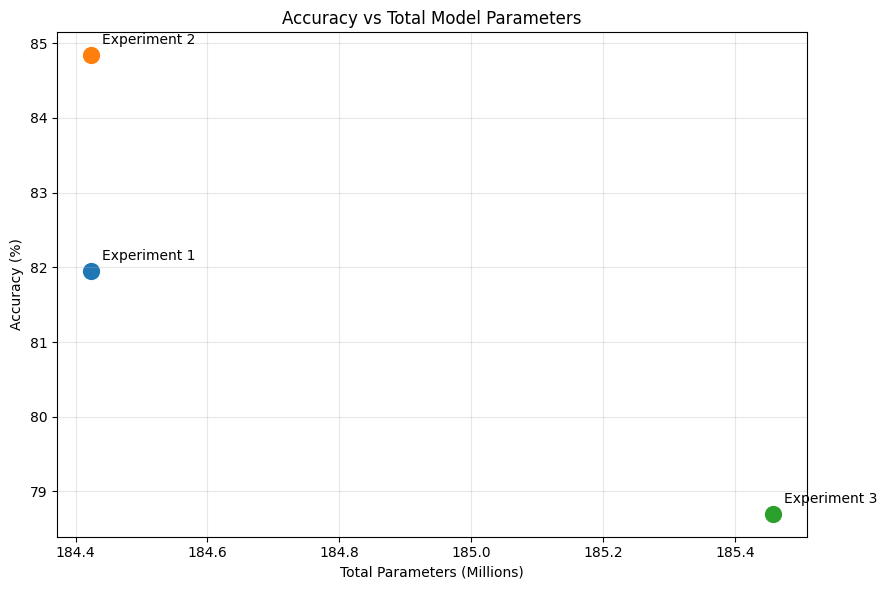

In [107]:

merged_df = performance_df.merge(
    parameter_df,
    on="Model"
)

plt.figure(figsize=(9, 6))

for _, row in merged_df.iterrows():

    plt.scatter(
        row["Total (M)"],
        row["Accuracy (%)"],
        s=130
    )

    plt.annotate(
        row["Model"],
        (row["Total (M)"], row["Accuracy (%)"]),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.xlabel("Total Parameters (Millions)")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs Total Model Parameters")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/accuracy_vs_parameters.png",
    dpi=300
)

plt.show()


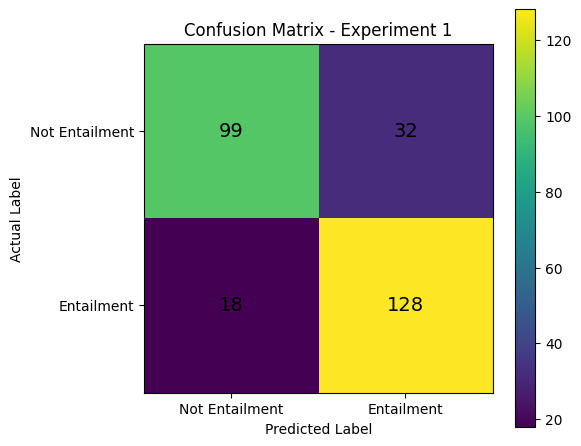

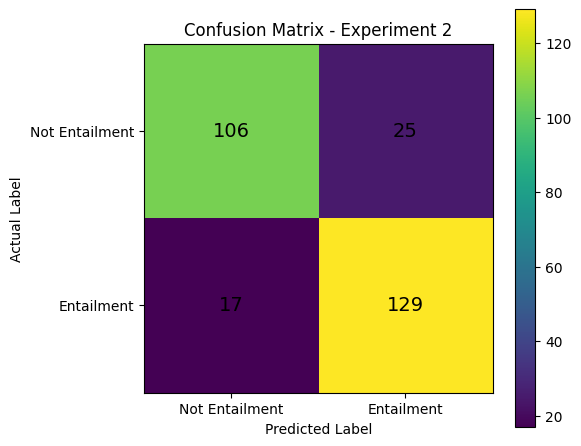

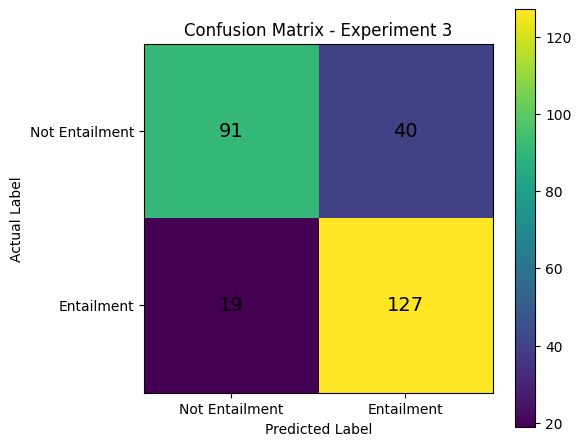

In [108]:

for name in MODEL_NAMES:

    pred = np.asarray(predictions_by_model[name])

    cm = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    image = ax.imshow(cm, interpolation="nearest")

    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Not Entailment", "Entailment"])
    ax.set_yticklabels(["Not Entailment", "Entailment"])

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                fontsize=14
            )

    fig.colorbar(image, ax=ax)
    plt.tight_layout()

    filename = name.lower().replace(" ", "_")

    plt.savefig(
        f"{OUTPUT_DIR}/{filename}_confusion_matrix.png",
        dpi=300
    )

    plt.show()


In [109]:

class_reports = []

for name in MODEL_NAMES:

    pred = np.asarray(predictions_by_model[name])

    report = classification_report(
        y_true,
        pred,
        labels=[0, 1],
        target_names=["Not Entailment", "Entailment"],
        output_dict=True,
        zero_division=0
    )

    for class_name in ["Not Entailment", "Entailment"]:

        class_reports.append({
            "Model": name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

class_report_df = pd.DataFrame(class_reports)

display(class_report_df.round(4))

class_report_df.to_csv(
    f"{OUTPUT_DIR}/class_wise_comparison.csv",
    index=False
)


,Model,Class,Precision,Recall,F1-score,Support
0,Experiment 1,Not Entailment,0.8462,0.7557,0.7984,131.0
1,Experiment 1,Entailment,0.8000,0.8767,0.8366,146.0
2,Experiment 2,Not Entailment,0.8618,0.8092,0.8346,131.0
3,Experiment 2,Entailment,0.8377,0.8836,0.8600,146.0
4,Experiment 3,Not Entailment,0.8273,0.6947,0.7552,131.0
5,Experiment 3,Entailment,0.7605,0.8699,0.8115,146.0


In [110]:

ID2LABEL = {
    0: "not_entailment",
    1: "entailment"
}

error_records = []

for name in MODEL_NAMES:

    pred = np.asarray(predictions_by_model[name])

    incorrect_indices = np.where(pred != y_true)[0]

    for i in incorrect_indices:

        error_records.append({
            "Model": name,
            "Index": int(i),
            "Premise": val_df.iloc[i]["premise"],
            "Hypothesis": val_df.iloc[i]["hypothesis"],
            "Actual": ID2LABEL[int(y_true[i])],
            "Predicted": ID2LABEL[int(pred[i])]
        })

errors_df = pd.DataFrame(error_records)

display(errors_df.head(20))

errors_df.to_csv(
    f"{OUTPUT_DIR}/error_analysis.csv",
    index=False
)

print("Total error records:", len(errors_df))


,Model,Index,Premise,Hypothesis,Actual,Predicted
0,Experiment 1,1,"Yet, we now are discovering that antibiotics a...",Bacteria is winning the war against antibiotics.,entailment,not_entailment
1,Experiment 1,2,Cairo is now home to some 15 million people - ...,15 million tonnes of rubbish are produced dail...,not_entailment,entailment
2,Experiment 1,3,"The Amish community in Pennsylvania, which num...",Pennsylvania has the biggest Amish community i...,not_entailment,entailment
3,Experiment 1,15,Deceased U.S. soldiers and their effects were ...,The U.S. military evacuated U.S. citizens.,not_entailment,entailment
4,Experiment 1,16,Mice given a substance found in red wine lived...,Mice fed with red wine lived longer despite a ...,not_entailment,entailment
5,Experiment 1,31,"Eric Harris and Dylan Klebold, seniors at the ...",13 persons were killed by two students in 1999.,entailment,not_entailment
6,Experiment 1,33,"On October 1 2001, EU and other countries intr...","In 2001, the EU introduced a six-month compuls...",not_entailment,entailment
7,Experiment 1,34,The Longest Day ever lengthens. The 25th anniv...,50th Anniversary of Normandy Landings lasts a ...,entailment,not_entailment
8,Experiment 1,38,Amazon shares fell nearly 4 percent following ...,Shares of Amazon fell 4 percent.,not_entailment,entailment
9,Experiment 1,41,The plan was released by Mr Dean on behalf of ...,Mr Dean is the Secretary of Health and Human S...,not_entailment,entailment


Total error records: 151


In [111]:

pred_matrix = np.column_stack([
    predictions_by_model[name]
    for name in MODEL_NAMES
])

disagreement_indices = np.where(
    np.any(
        pred_matrix != pred_matrix[:, [0]],
        axis=1
    )
)[0]

disagreement_df = val_df.iloc[
    disagreement_indices
][["idx", "premise", "hypothesis", "label"]].copy()

disagreement_df["Experiment 1"] = pred_matrix[disagreement_indices, 0]
disagreement_df["Experiment 2"] = pred_matrix[disagreement_indices, 1]
disagreement_df["Experiment 3"] = pred_matrix[disagreement_indices, 2]

disagreement_df.to_csv(
    f"{OUTPUT_DIR}/model_disagreements.csv",
    index=False
)

print("Number of examples with model disagreement:", len(disagreement_df))
display(disagreement_df.head(15))


Number of examples with model disagreement: 54


,idx,premise,hypothesis,label,Experiment 1,Experiment 2,Experiment 3
2,2,Cairo is now home to some 15 million people - ...,15 million tonnes of rubbish are produced dail...,not_entailment,1,1,0
3,3,"The Amish community in Pennsylvania, which num...",Pennsylvania has the biggest Amish community i...,not_entailment,1,0,1
12,12,"In Nigeria, by far the most populous country i...",2.7 percent of the people infected with HIV li...,not_entailment,0,0,1
15,15,Deceased U.S. soldiers and their effects were ...,The U.S. military evacuated U.S. citizens.,not_entailment,1,0,0
18,18,Teenage sensation Wayne Rooney powered England...,France participates in Euro 2004.,entailment,1,1,0
34,34,The Longest Day ever lengthens. The 25th anniv...,50th Anniversary of Normandy Landings lasts a ...,entailment,0,1,1
35,35,The Qin (from which the name China is derived)...,Qin Shi Huang was the first Chinese Emperor.,not_entailment,0,0,1
36,36,Hands Across the Divide was formed in March 20...,Cyprus was divided into two parts in March 2001.,not_entailment,0,0,1
37,37,The IOC meeting will also review reports submi...,"Before Salt Lake City, Winter Olympic Games to...",entailment,1,1,0
41,41,The plan was released by Mr Dean on behalf of ...,Mr Dean is the Secretary of Health and Human S...,not_entailment,1,0,0


In [112]:

# Replace None only when the instructor provides actual values.

INSTRUCTOR_BASELINE = {
    "Accuracy (%)": None,
    "Macro F1 (%)": None,
    "Total Parameters": None,
    "Trainable Parameters": None
}

baseline_row = {
    "Model": "Instructor Baseline",
    **INSTRUCTOR_BASELINE
}

our_rows = []

for _, row in performance_df.iterrows():

    params = parameter_df[
        parameter_df["Model"] == row["Model"]
    ].iloc[0]

    our_rows.append({
        "Model": row["Model"],
        "Accuracy (%)": row["Accuracy (%)"],
        "Macro F1 (%)": row["Macro F1 (%)"],
        "Total Parameters": params["Total Parameters"],
        "Trainable Parameters": params["Trainable Parameters"]
    })

baseline_comparison_df = pd.DataFrame(
    [baseline_row] + our_rows
)

display(baseline_comparison_df)

baseline_comparison_df.to_csv(
    f"{OUTPUT_DIR}/instructor_baseline_comparison.csv",
    index=False
)


,Model,Accuracy (%),Macro F1 (%),Total Parameters,Trainable Parameters
0,Instructor Baseline,NaN,NaN,NaN,NaN
1,Experiment 1,81.95,81.75,184423682.0,184423682.0
2,Experiment 2,84.84,84.73,184423682.0,184423682.0
3,Experiment 3,78.70,78.33,185458180.0,1034498.0


In [113]:

best_model_row = performance_df.loc[
    performance_df["Macro F1 (%)"].idxmax()
]

summary = {
    "dataset": "RTE Development Set",
    "number_of_examples": len(y_true),
    "best_model": best_model_row["Model"],
    "best_accuracy": float(best_model_row["Accuracy (%)"]),
    "best_macro_f1": float(best_model_row["Macro F1 (%)"]),
    "models": {}
}

for name in MODEL_NAMES:

    perf = performance_df[
        performance_df["Model"] == name
    ].iloc[0]

    params = parameter_df[
        parameter_df["Model"] == name
    ].iloc[0]

    summary["models"][name] = {
        "accuracy": float(perf["Accuracy (%)"]),
        "precision": float(perf["Precision (%)"]),
        "recall": float(perf["Recall (%)"]),
        "macro_f1": float(perf["Macro F1 (%)"]),
        "correct": int(perf["Correct"]),
        "incorrect": int(perf["Incorrect"]),
        "total_parameters": int(params["Total Parameters"]),
        "trainable_parameters": int(params["Trainable Parameters"]),
        "trainable_percentage": float(params["Trainable (%)"])
    }

with open(
    f"{OUTPUT_DIR}/final_comparison_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))


{
    "dataset": "RTE Development Set",
    "number_of_examples": 277,
    "best_model": "Experiment 2",
    "best_accuracy": 84.84,
    "best_macro_f1": 84.73,
    "models": {
        "Experiment 1": {
            "accuracy": 81.95,
            "precision": 82.31,
            "recall": 81.62,
            "macro_f1": 81.75,
            "correct": 227,
            "incorrect": 50,
            "total_parameters": 184423682,
            "trainable_parameters": 184423682,
            "trainable_percentage": 100.0
        },
        "Experiment 2": {
            "accuracy": 84.84,
            "precision": 84.97,
            "recall": 84.64,
            "macro_f1": 84.73,
            "correct": 235,
            "incorrect": 42,
            "total_parameters": 184423682,
            "trainable_parameters": 184423682,
            "trainable_percentage": 100.0
        },
        "Experiment 3": {
            "accuracy": 78.7,
            "precision": 79.39,
            "recall": 78.23,
        

In [114]:

import shutil

ZIP_PATH = shutil.make_archive(
    f"{BASE_DIR}/RTE_Final_Comparison",
    "zip",
    OUTPUT_DIR
)

print("All comparison files saved.")
print("ZIP file:", ZIP_PATH)

print("\nFiles included:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(file)


All comparison files saved.
ZIP file: /kaggle/working/RTE_Challenge/RTE_Final_Comparison.zip

Files included:
accuracy_f1_comparison.png
accuracy_vs_parameters.png
class_wise_comparison.csv
error_analysis.csv
experiment_1_confusion_matrix.png
experiment_2_confusion_matrix.png
experiment_3_confusion_matrix.png
final_comparison_summary.json
hyperparameter_comparison.csv
instructor_baseline_comparison.csv
model_disagreements.csv
parameter_comparison.csv
parameter_comparison.png
performance_comparison.csv
precision_recall_comparison.png
